# Benchmark: StarSim (D. Baroch) vs SunSim — photometry and RV, outputs, time and RAM

The original StarSim of **David Baroch** (`starsim_david`, version 3.0.1, the module folder, **not installed**) and SunSim simulate the
same star with the same active regions, in **photometry** (light curve) and in **RV mode** (CCF with a line mask and its RV, FWHM, BIS
and contrast): the part that both codes can do. For every simulation, the outputs are compared and the time and the memory (RAM) of
every step are measured.

| | StarSim (D. Baroch) | SunSim |
|---|---|---|
| code | the module `starsim` of the folder `starsim_david` (path of `local_paths.ini`), copied to a temporary folder (it reads its configuration, masks, filters and models from its own folder; the original folder is not modified). One line of the copy is changed for NumPy ≥ 2 (`float()` of a 1-element array in `compute_planet_pos`, same value) | the `sunsim` package of this repository |
| set-up | `starsim.conf` and the spot map (`spot_map` set after `StarSim(conf)`) | Python objects |
| one simulation | `compute_forward(t, observables)`: reads the models, builds the grids and computes the time series at every call | `spectra` (Phoenix interpolation), `grids` (`flux_grid`, `CCF_grid`), `simulation` (`StarSim` + `generate_timeseries`); spectra and grids can be reused |
| mode | `simulation_mode = grid` (the `fast` mode is compared in section 9) | — |

**The common case, set up identically in both codes.**
* **Models**: the same Phoenix files (`models` of the old StarSim): SPECINT (`Phoenix_mu`) for the light curve and the brightness of
  the rings, HiRes (`Phoenix`) for the CCFs. Temperatures on grid points of the models (T_eff = 5800 K, log g = 4.5, spot 5300 K): the
  SPECINT models of different temperatures tabulate different μ, which StarSim (D. Baroch) adds without interpolation in μ (see the
  TRAPPIST-1 benchmark); on grid points no such interpolation is needed. The facula (5830 K) only uses HiRes models.
* **Wavelengths**: StarSim (D. Baroch) uses one range (`wavelength_lower_limit`, `wavelength_upper_limit` = 3700-9500 Å) for the light
  curve (with the filter `TJO_R.dat`), for the brightness of the rings in RV and for the flattening of the HiRes spectra; the CCF mask
  (`HARPS_G20.mas`, lines not weighted) must be inside it. SunSim uses the same range for each.
* **Faculae**: StarSim (D. Baroch) puts a facula of radius r √(1+Q) around every spot (Q = `facular_area_ratio`); its brightness is the
  quiet photosphere times ((T_ph + ΔT(μ)) / T_fac)⁴, ΔT(μ) = 250.9 − 407.4 μ + 190.9 μ² K, and its CCF the one of the HiRes spectrum at
  T_fac. SunSim gets a facula `active_region('fc', r √(1+Q))` with the same centre, the same brightness and the same CCF.
* **CCFs**: mask CCF on the Phoenix pixels, normalised to [0, 1]; the bisector of the CCF of every surface is removed, and the CIFIST
  bisector (photosphere, μ-dependent) or the Dumusque bisector (spots, faculae) times `convective_shift` is added. SunSim: `CCF_grid`
  in the `centre` mode with the same bisector functions (`bisector=`); the CCF of every ring weighted by its brightness (`mu_ratio`).
* **Outputs** as `compute_forward`: light curve / quiet star; RV − RV of the quiet star (+ Keplerian RV); contrast / contrast of the
  quiet star; FWHM; BIS (10-40 % minus 60-90 %).

**Known differences** (from the code of StarSim (D. Baroch); they are measured in sections 6-8):
1. *Central cell, photometry*: the brightness of the central cell is taken as `bph[i]` with `i` the index left by a previous loop (the
   number of spots − 1) instead of 0 (`loop_generate_rotating_lc_nb`). Wrong when there are several spots and one covers the centre
   of the disc (section 8, `three spots`); the RV loop is correct.
2. *Faculae partly covered*: the facula fraction of a cell is its coverage minus the coverage of its own spot; SunSim subtracts the
   spots that cover it. The same for a spot inside its own facula.
3. *Differential rotation in RV*: the regions move with B (1.698 sin²lat + 2.346 sin⁴lat) (as SunSim with (1.698 B, 2.346 B)), but the
   rotation velocity of the cells uses a period 1/(1/P + B sin²lat/360): another law. Photometry is the same; RV differs (section 8).
4. *Planets*: the fraction of a cell covered by a planet is a linear ramp in the distance (too deep for planets smaller than a cell).
   SunSim uses it with `planet_coverage='ramp'`; its default (`'area'`, the exact area) is shown too (section 8).
5. *Dumusque bisector*: StarSim (D. Baroch) uses the polynomial of Dumusque (2014) without the +0.4 km/s constant that SunSim's
   `dumusque_bisector` adds; SunSim gets David's polynomial here. Matters only with `convective_shift ≠ 0`.
6. *μ angles of the photosphere*: `compute_forward` reads the SPECINT spectra of the photosphere and then of the spot into the same
   variable of the angles (`acd`), so the photosphere is interpolated in μ with the angles of the spot model (5300 K: up to 0.0026 from
   those of 5800 K). This changes the brightness of the photosphere at the limb, so the contrast of the regions, by ~0.1 % (light
   curve and brightness of the rings in RV). Reproduced: SunSim takes the photosphere at the angles of the spot model
   (`interpolate_phoenix_mu(..., mu_angles=spot spectra)`); `own_angles=True` gives every model its own angles, shown for information.
7. *Numerics*: the light curve is a sum over the wavelengths (SunSim: trapezoidal integral; identical with the filter, ~1e-4 relative
   in the brightness of the rings in RV); the gaussian fit of the CCF is `scipy.optimize.curve_fit` (SunSim: its own Levenberg-
   Marquardt, same model).

## 1. Settings

* `sunsim_python`: Python of the environment `sunsim`, which runs every simulation of both codes (each in a new process);
* `david_folder`: the module folder of StarSim (D. Baroch); `SunSim_folder`; `models_folder`: Phoenix models (`Phoenix_mu`, `Phoenix`);
* `star`: star, regions and instrument, the same for every run (Q = facula / spot area ratio, CB = convective shift, B = differential
  rotation [deg/day]);
* `n_processes`: number of new processes for every case (cold measurements: import, first run, new session = import + first run;
  median over the processes). In every process, after the first run, the simulation is repeated `n_next` times (at least `min_next`,
  and no more once these repetitions took `max_warm_seconds`): the **next runs** (median of all of them);
* `reference` (50 rings, 100 epochs over one rotation, one spot + facula on the equator) and `sweeps`: every parameter is changed in
  turn from the reference.

In [1]:
from pathlib import Path
import os, sys, json, time, shutil, tempfile, platform, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sunsim
from sunsim import local_path   # paths of this computer: local_paths.ini (see local_paths.example.ini)

sunsim_python = str(local_path('sunsim_python', default=sys.executable))
david_folder = str(local_path('starsim_david'))          # StarSim of D. Baroch (module folder, not installed)
SunSim_folder = str(Path(sunsim.__file__).resolve().parents[1])
models_folder = str(local_path('phoenix_models'))           # Phoenix_mu (SPECINT) and Phoenix (HiRes)

star = dict(T_eff=5800.0, dT_spot=500.0, dT_fac=30.0, logg=4.5,       # [K], [K], [K], [cgs]
            radius=1.0, mass=1.0, P_rot=25.05, inclination=90.0,        # [Rsun], [Msun], [d], [deg] (90 = equator-on)
            Q=3.0, CB=0.0, B=0.0,                                       # facula/spot area, convective shift, diff. rotation [deg/d]
            band=[3700.0, 9500.0], filter='TJO_R.dat', mask='HARPS_G20.mas',   # files of StarSim (D. Baroch)
            rv_range=18.0, rv_step=0.25,                                # CCF velocity grid [km/s]
            evo_law='constant', planet=None, simulation_mode='grid', planet_coverage='ramp')

n_processes = 3
n_next, min_next, max_warm_seconds = 10, 3, 10.0
reference = {'n_rings': 50, 'n_epochs': 100, 'n_regions': 1}
sweeps = {'n_rings': [10, 20, 50, 100, 200, 500], 'n_epochs': [100, 1000, 5000], 'n_regions': [1, 10, 30]}
output_rings = [10, 50, 500]          # outputs compared (section 6): one run each at these numbers of rings, not timed
modes = ['phot', 'rv']
mode_names = {'phot': 'photometry', 'rv': 'RV'}
versions = ['David', 'SunSim']


def make_regions(n):
    """n regions (colatitude [deg], longitude [deg], spot radius [deg]): the reference spot, then random ones."""
    rng = np.random.default_rng(1)
    return [[90.0, 180.0, 8.0]] + [[rng.uniform(30, 150), rng.uniform(0, 360), rng.uniform(2, 6)] for _ in range(n - 1)]


def spot_rows(regions):
    """Spot map of StarSim (D. Baroch), no type column: appearance time, lifetime, colatitude, longitude, c1, c2, c3
    (constant radius c1, present at all the epochs)."""
    return [[-1e9, 2e9, colat, lon, r, 0.0, 0.0] for colat, lon, r in regions]


for p in [sunsim_python, os.path.join(david_folder, 'starsim', 'starsim.py'), SunSim_folder,
          os.path.join(david_folder, 'starsim', 'masks', star['mask']),
          os.path.join(david_folder, 'starsim', 'models', 'filters', star['filter']),
          os.path.join(models_folder, 'Phoenix_mu'), os.path.join(models_folder, 'Phoenix')]:
    assert os.path.exists(p), p

work_dir = tempfile.mkdtemp(prefix='benchmark_starsim_david_')
# StarSim (D. Baroch) reads its configuration, spot map, masks, filters and models from the folder of the module: the module
# is copied (code, masks, filters) and the Phoenix folders are linked, so that nothing is written in the original folder
david_work = os.path.join(work_dir, 'david')
shutil.copytree(os.path.join(david_folder, 'starsim'), os.path.join(david_work, 'starsim'),
                ignore=shutil.ignore_patterns('.*', '__pycache__', '*.nbi', '*.nbc', 'models'))
os.makedirs(os.path.join(david_work, 'starsim', 'models'))
shutil.copytree(os.path.join(david_folder, 'starsim', 'models', 'filters'), os.path.join(david_work, 'starsim', 'models', 'filters'))
for sub in ('Phoenix', 'Phoenix_mu'):
    os.symlink(os.path.join(models_folder, sub), os.path.join(david_work, 'starsim', 'models', sub))
# NumPy >= 2 compatibility of the copy (the only change to the code of StarSim (D. Baroch)): compute_planet_pos converts
# 1-element arrays with float(), which NumPy 2 refuses (NumPy 1.x gave the same value with a deprecation warning)
spectra_py = os.path.join(david_work, 'starsim', 'spectra.py')
code_david = open(spectra_py).read()
old_line = 'pos=np.array([float(rhopl), float(thpl), self.planet_radius])'
assert code_david.count(old_line) == 1
open(spectra_py, 'w').write(code_david.replace(old_line, 'pos=np.array([float(rhopl[0]), float(thpl[0]), self.planet_radius])'))
paths = dict(david_work=david_work, SunSim_folder=SunSim_folder, models_folder=models_folder)

# caches of both codes in the work folder: compiled Numba functions and Python bytecode
run_env = dict(os.environ, NUMBA_CACHE_DIR=os.path.join(work_dir, 'numba_cache'),
               PYTHONPYCACHEPREFIX=os.path.join(work_dir, 'pycache'), MPLBACKEND='Agg')
probe_path = os.path.join(work_dir, 'probe.py')
runner_david = os.path.join(work_dir, 'run_david.py')
runner_sunsim = os.path.join(work_dir, 'run_sunsim.py')
print('machine: %s, %d CPUs' % (platform.platform(), os.cpu_count()))
print('work folder (copy of StarSim (D. Baroch), scripts, configuration files, outputs):', work_dir)

machine: macOS-26.6.2-arm64-arm-64bit, 10 CPUs
work folder (copy of StarSim (D. Baroch), scripts, configuration files, outputs): /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim_david_bds477c6


## 2. Measurement

Three scripts are written in the work folder:

* `probe.py` (the same as in the StarSim v4 benchmark) measures every step of a run. **Time**: `time.perf_counter`. **RAM**: the
  resident set size (RSS) of the process, read every 2 ms by a thread (the peak of a step includes the temporary arrays freed before
  it ends); `ru_maxrss` gives the peak of the whole process.
* `run_david.py`: one run of StarSim (D. Baroch). It writes the configuration (its own `starsim.conf` with the settings of the run),
  then `import`, `init` = `StarSim(conf)` + spot map, and `compute_forward` repeated (its printed progress is discarded).
* `run_sunsim.py`: one run of SunSim: `import`, then repeated `spectra`, `grids` and `simulation`.

| step | StarSim (D. Baroch) | SunSim |
|---|---|---|
| import | `import starsim` (from the copy) | `sunsim` |
| spectra | inside `compute_forward` | SPECINT of the photosphere and the spot; RV: + HiRes of the 3 surfaces and the mask |
| grids | inside `compute_forward` | photometry: 3 `flux_grid`; RV: brightness of the rings (`mu_ratio`) and 3 `CCF_grid` |
| time series | inside `compute_forward` | `StarSim(...)` + `generate_timeseries()` |

**What is compared.** *new session* = import + first run (median over the processes): one simulation in a new Python session.
*next runs*: one more simulation in the same session (StarSim (D. Baroch): `compute_forward` again; SunSim: spectra + grids +
simulation again, the Phoenix files are kept in memory). *grids reused* (SunSim only): a simulation with the grids already built,
for other epochs, regions or planets; StarSim (D. Baroch) has no equivalent (every `compute_forward` rebuilds everything).

In [2]:
%%writefile {probe_path}
"""Time and memory of the steps of one run (imported by the two runners, each run in its own Python process).

probe = Probe()
with probe.step('name'): ...      -> probe.steps gets {'step', 'time [s]', 'rss before [MB]', 'rss after [MB]', 'rss peak [MB]'}
probe.finish(**extra)              -> prints the result as one JSON line (read by the notebook)

The memory is the resident set size (RSS) of the process: everything it holds in RAM (Python objects, numpy arrays,
Numba compiled code, libraries). A thread reads it every `interval` seconds, so the peak of a step includes the
temporary arrays that are freed before the step ends."""
import json, resource, sys, threading, time
import psutil

MB = 1e6


class Probe:
    def __init__(self, interval=0.002):
        self.proc = psutil.Process()
        self.interval = interval
        self.steps = []
        self.rss_start = self.rss()
        self._peak = self.rss_start
        self._stop = False
        self._thread = threading.Thread(target=self._watch, daemon=True)
        self._thread.start()

    def rss(self):
        return self.proc.memory_info().rss / MB

    def _watch(self):
        while not self._stop:
            r = self.rss()
            if r > self._peak:
                self._peak = r
            time.sleep(self.interval)

    def step(self, name):
        probe = self

        class _Step:
            def __enter__(self):
                self.before = probe.rss()
                probe._peak = self.before
                self.t0 = time.perf_counter()

            def __exit__(self, *exc):
                dt = time.perf_counter() - self.t0
                after = probe.rss()
                probe.steps.append({'step': name, 'time [s]': dt, 'rss before [MB]': self.before,
                                    'rss after [MB]': after, 'rss peak [MB]': max(probe._peak, after)})
        return _Step()

    def finish(self, **extra):
        self._stop = True
        self._thread.join()
        # ru_maxrss: peak of the whole process, in bytes on macOS and in kB on Linux
        maxrss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        maxrss = maxrss / MB if sys.platform == 'darwin' else maxrss * 1e3 / MB
        out = {'rss start [MB]': self.rss_start, 'rss max process [MB]': maxrss, 'steps': self.steps,
               'python': sys.version.split()[0]}
        for lib in ('numpy', 'numba', 'scipy', 'astropy'):
            if lib in sys.modules:
                out[lib] = sys.modules[lib].__version__
        if 'numba' in sys.modules:
            out['numba threads'] = sys.modules['numba'].get_num_threads()
        out.update(extra)
        print('BENCHMARK_RESULT ' + json.dumps(out))

Writing /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim_david_bds477c6/probe.py


In [3]:
%%writefile {runner_david}
"""One run of StarSim (D. Baroch), from its copy in the work folder. Usage: python run_david.py settings.json
Steps: import, init = StarSim(conf) + spot map, compute_forward 1 (first run), then compute_forward 2, 3, ... (next runs)."""
import io, json, os, sys, contextlib
from configparser import ConfigParser
s = json.load(open(sys.argv[1]))
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from probe import Probe
probe = Probe()

import numpy as np
with probe.step('import'):
    sys.path.insert(0, s['david_work'])
    import starsim
assert os.path.dirname(starsim.__file__).startswith(s['david_work']), starsim.__file__

# configuration: the starsim.conf of the module with the settings of the run
conf = ConfigParser(inline_comment_prefixes='#')
conf.read(os.path.join(s['david_work'], 'starsim', 'starsim.conf'))
pl = s['planet'] or {}
values = {
    'files': {'filter_name': s['filter']},
    'general': {'simulation_mode': s['simulation_mode'], 'n_grid_rings': s['n_rings'],
                'wavelength_lower_limit': s['band'][0], 'wavelength_upper_limit': s['band'][1]},
    'rv': {'ccf_template': 'mask', 'ccf_mask': s['mask'], 'ccf_weight_lines': 0, 'ccf_rv_range': s['rv_range'],
           'ccf_rv_step': s['rv_step']},
    'star': {'temperature_photosphere': s['T_eff'], 'spot_T_contrast': s['dT_spot'], 'facula_T_contrast': s['dT_fac'],
             'facular_area_ratio': s['Q'], 'convective_shift': s['CB'], 'rotation_period': s['P_rot'],
             'radius': s['radius'], 'mass': s['mass'], 'logg': s['logg'], 'inclination': s['inclination'],
             'differential_rotation': s['B']},
    'LD': {'use_phoenix_limb_darkening': 1},
    'spots': {'plot_grid_map': 0, 'spots_evo_law': s['evo_law'], 'reference_time': 0.0},
    'planet': {'simulate_planet': int(bool(pl)), 'planet_period': pl.get('period', 1.0),
               'planet_transit_t0': pl.get('t0', 0.0), 'planet_radius': pl.get('radius', 0.1),
               'planet_impact_param': pl.get('b', 0.0), 'planet_esinw': pl.get('esinw', 0.0),
               'planet_ecosw': pl.get('ecosw', 0.0), 'planet_spin_orbit_angle': pl.get('spin_orbit', 0.0),
               'planet_semi_amplitude': pl.get('K', 0.0)}}
for section, kv in values.items():
    for k, v in kv.items():
        conf.set(section, k, str(v))
conf_path = os.path.join(s['work_dir'], s['name'] + '.conf')
with open(conf_path, 'w') as f:
    conf.write(f)

times = np.linspace(*s['t_range'], s['n_epochs'])
with probe.step('init'):
    ss = starsim.StarSim(conf_path)                         # an absolute path: used as is
    ss.spot_map = np.atleast_2d(np.array(s['spot_rows'], dtype=float))
observables = ['lc'] if s['mode'] == 'phot' else ['rv', 'bis', 'fwhm', 'contrast']
k, warm = 0, 0.0
while True:
    k += 1
    with probe.step('compute_forward %d' % k):
        with contextlib.redirect_stdout(io.StringIO()):      # progress printed at every epoch
            ss.compute_forward(observables, t=times)
    if k > 1:
        warm += probe.steps[-1]['time [s]']
    if k - 1 >= s['n_next'] or (k - 1 >= s['min_next'] and warm >= s['max_warm_seconds']):
        break

r = ss.results
out = dict(ff_sp=r['ff_sp'], ff_fc=r['ff_fc'], ff_pl=r['ff_pl'])
if s['mode'] == 'phot':
    out['flux'] = r['lc']
else:
    out.update(rv=r['rv'], fwhm=r['fwhm'], bis=r['bis'], contrast=r['contrast'], ccf_rv=r['CCF'][0], ccf=r['CCF'][1:])
np.savez(os.path.join(s['work_dir'], s['name'] + '.npz'), times=times, **{k: np.asarray(v, dtype=float) for k, v in out.items()})
probe.finish()

Writing /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim_david_bds477c6/run_david.py


In [4]:
%%writefile {runner_sunsim}
"""One run of SunSim, set up as StarSim (D. Baroch). Usage: python run_sunsim.py settings.json
Steps, repeated: spectra (Phoenix spectra, mask), grids (flux grids or brightness of the rings + CCF grids),
simulation (StarSim + generate_timeseries)."""
import json, os, sys
s = json.load(open(sys.argv[1]))
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from probe import Probe
probe = Probe()

import numpy as np
with probe.step('import'):
    sys.path.insert(0, s['SunSim_folder'])
    from sunsim import (StarSim, flux_grid, CCF_grid, active_region, planet, interpolate_phoenix_mu, interpolate_phoenix,
                        mask_weights)
    from sunsim.old_config import _cifist          # CIFIST bisectors of the old code (cifist_coeff_interpolate)

N, P = s['n_rings'], s['P_rot']
lo, hi = s['band']
inclination = np.deg2rad(90 - s['inclination'])      # SunSim: radians, 0 = equator-on
T_ph, T_sp, T_fc = s['T_eff'], s['T_eff'] - s['dT_spot'], s['T_eff'] + s['dT_fac']
specint = os.path.join(s['models_folder'], 'Phoenix_mu')
hires = os.path.join(s['models_folder'], 'Phoenix')
david_files = os.path.join(s['david_work'], 'starsim')
filter_path = os.path.join(david_files, 'models', 'filters', s['filter'])
times = np.linspace(*s['t_range'], s['n_epochs'])
Q = s['Q']

# regions: every spot of the spot map, and a concentric facula of radius r sqrt(1 + Q) (Q > 0); evolution laws as StarSim (D. Baroch)
regions = []
for t0, life, colat, lon, c1, c2, c3 in s['spot_rows']:
    if s['evo_law'] == 'constant':
        ev = None
    elif s['evo_law'] == 'linear':
        ev = lambda dt, size, c1=c1, c2=c2, T=life: c1 + dt * (c2 - c1) / T
    else:
        raise ValueError(s['evo_law'])
    regions.append(active_region('sp', c1, colat, lon, appearance_time=t0, lifetime=life, evolution=ev))
    if Q > 0:
        evf = None if ev is None else (lambda dt, size, ev=ev: ev(dt, size) * np.sqrt(1 + Q))
        regions.append(active_region('fc', c1 * np.sqrt(1 + Q), colat, lon, appearance_time=t0, lifetime=life, evolution=evf))
pl = None
if s['planet']:
    p = s['planet']
    a = 4.2097 * p['period']**(2 / 3) * s['mass']**(1 / 3) / s['radius']       # semi-major axis of StarSim (D. Baroch)
    pl = planet(planet_period=p['period'], planet_transit_t0=p['t0'], planet_radius=p['radius'], planet_semi_major_axis=a,
                planet_impact_param=p['b'], planet_esinw=p.get('esinw', 0.0), planet_ecosw=p.get('ecosw', 0.0),
                planet_spin_orbit_angle=np.deg2rad(p.get('spin_orbit', 0.0)), planet_semi_amplitude=p.get('K', 0.0))


def facula_factor(mu):
    """Brightness of the faculae relative to the photosphere: ((T_ph + dT(mu)) / T_fc)^4 (StarSim (D. Baroch))."""
    return ((T_ph + 250.9 - 407.4 * mu + 190.9 * mu**2) / T_fc)**4


def brightness(spectra, filt):
    """Flux of one cell of every ring (photometry grid) in the band, with or without the filter."""
    g = flux_grid(N, spectra, 'x', filt, lo, hi, rotation_period=P, inclination=inclination, stellar_radius=s['radius'],
                  mode='photometry')
    g.built_grid()
    return g


DUMUSQUE = np.poly1d([-1.51773453, 3.52774949, -3.18794328, 1.22541774, -0.22479665])   # dumusque_coeffs of StarSim (D. Baroch)
bisectors = {'qp': lambda mu: _cifist(mu), 'sp': lambda mu: DUMUSQUE, 'fc': lambda mu: DUMUSQUE}

k, warm = 0, 0.0
while True:
    k += 1
    t_rep = len(probe.steps)
    with probe.step('spectra %d' % k):
        # SPECINT cut at lo < wavelength < hi (overhead 0), the pixels of StarSim (D. Baroch)
        sp = interpolate_phoenix_mu(specint, T_sp, s['logg'], wavelength_lower_limit=lo, wavelength_upper_limit=hi, overhead=0)
        # as StarSim (D. Baroch): the photosphere intensities at the mu of the spot model (own_angles: at their own mu)
        q = interpolate_phoenix_mu(specint, T_ph, s['logg'], wavelength_lower_limit=lo, wavelength_upper_limit=hi, overhead=0,
                                   mu_angles=None if s.get('own_angles') else sp)
        if s['mode'] == 'rv':
            wvm, fm = mask_weights(os.path.join(david_files, 'masks', s['mask']), medium='vacuum')
            # HiRes spectra flattened as StarSim (D. Baroch): continuum of 20 bins between lo - 1 and hi + 1 A
            high = {name: interpolate_phoenix(hires, T, s['logg'], wavelength_lower_limit=lo, wavelength_upper_limit=hi,
                                              normalize=True) for name, T in (('qp', T_ph), ('sp', T_sp), ('fc', T_fc))}
    with probe.step('grids %d' % k):
        if s['mode'] == 'phot':
            gq, gs = brightness(q, filter_path), brightness(sp, filter_path)
            gf = gq.grid * facula_factor(gq.amu)
            grids = dict(flux_grid_qp=gq.grid, flux_grid_sp=gs.grid, flux_grid_fc=gf)
            mode = ['photometry']
        else:
            bq, bs = brightness(q, None), brightness(sp, None)              # no filter: brightness of the rings in the band
            norm = bq.total_brightness / (4 * np.pi)
            ratio = {'qp': bq.grid / bq.parea / norm, 'sp': bs.grid / bs.parea / norm}
            ratio['fc'] = ratio['qp'] * facula_factor(bq.amu)
            rv_grid = 1000 * np.arange(-s['rv_range'], s['rv_range'] + s['rv_step'], s['rv_step'])
            c = {}
            for name in ('qp', 'sp', 'fc'):
                c[name] = CCF_grid(N, high[name], rv_grid, wvm, fm, convective_blueshift=s['CB'], phoenix_resolution=True,
                                   normalization=True, medium='vacuum', mask_medium='vacuum', mu_ratio=ratio[name])
                c[name].built_grid(bisector=bisectors[name], kind_interp='cubic')
            grids = dict(ccf_grid_qp=c['qp'], ccf_grid_sp=c['sp'], ccf_grid_fc=c['fc'])
            mode = ['ccf']
    with probe.step('simulation %d' % k):
        ss = StarSim(times, N, inclination=inclination, rotation_period=P, stellar_radius=s['radius'],
                     differential_rotation=(1.698 * s['B'], 2.346 * s['B']), active_regions_map=regions, planet=pl,
                     mode=mode, planet_coverage=s['planet_coverage'], **grids)
        ss.generate_timeseries(verbose=False)
    if k > 1:
        warm += sum(st['time [s]'] for st in probe.steps[t_rep:])
    if k - 1 >= s['n_next'] or (k - 1 >= s['min_next'] and warm >= s['max_warm_seconds']):
        break

out = dict(ff_sp=ss.ff_sp, ff_fc=ss.ff_fc, ff_pl=ss.ff_pl)
if s['mode'] == 'phot':
    out['flux'] = ss.flux_var / gq.total_brightness
else:
    # zero points as compute_forward: RV and contrast of the quiet star (whole disc, no region)
    quiet = StarSim(times[:1], N, inclination=inclination, rotation_period=P, stellar_radius=s['radius'],
                    differential_rotation=(1.698 * s['B'], 2.346 * s['B']), mode=['ccf'], **grids)
    quiet.generate_timeseries(ccf_params=False, verbose=False)
    rv0, c0, _, _, _, _ = ss.compute_ccf_params(rv=ss.ccf_rv, ccf=[quiet.ccf_var[0]])
    out.update(rv=ss.rv_var - rv0[0], fwhm=ss.fwhm_var, bis=ss.bis_var, contrast=ss.contrast_var / c0[0],
               ccf_rv=ss.ccf_rv, ccf=ss.ccf_var)
np.savez(os.path.join(s['work_dir'], s['name'] + '.npz'), times=times, **{k: np.asarray(v, dtype=float) for k, v in out.items()})
probe.finish()

Writing /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim_david_bds477c6/run_sunsim.py


`run(version, mode, case)` writes the settings of one run (`.json`), runs it with `sunsim_python` in a new process (with the caches of
`run_env`) and returns its measurements (and, with `keep_outputs`, its outputs).

**Warm-up.** One small run of each version and mode first, not measured: it writes the compiled Numba functions and the bytecode of
both codes in the work folder, as after their first use in an environment.

**Check of the inputs.** The bisector functions given to SunSim are compared with the ones of StarSim (D. Baroch) (CIFIST at every μ,
Dumusque).

In [5]:
def run(version, mode, case, process=0, keep_outputs=False, tag='', **override):
    """One run in its own new process. version: 'David' or 'SunSim'; mode: 'phot' or 'rv'; case: {'n_rings', 'n_epochs',
    'n_regions'}; override: settings that replace those of `star` (e.g. Q, regions, planet, t_range, simulation_mode).
    Returns the measurements (and the outputs of the last simulation if keep_outputs)."""
    name = '%s_%s_N%d_t%d_r%d_p%d%s' % (version, mode, case['n_rings'], case['n_epochs'], case['n_regions'], process, tag)
    settings = dict(star, **paths, mode=mode, name=name, work_dir=work_dir, n_next=n_next, min_next=min_next,
                    max_warm_seconds=max_warm_seconds, n_rings=case['n_rings'], n_epochs=case['n_epochs'],
                    t_range=[0.0, star['P_rot']], regions=make_regions(case['n_regions']))
    settings.update(override)
    settings['spot_rows'] = settings.get('spot_rows') or spot_rows(settings['regions'])
    settings_path = os.path.join(work_dir, name + '.json')
    with open(settings_path, 'w') as f:
        json.dump(settings, f)
    script = runner_david if version == 'David' else runner_sunsim
    p = subprocess.run([sunsim_python, script, settings_path], capture_output=True, text=True, env=run_env)
    lines = [l for l in p.stdout.splitlines() if l.startswith('BENCHMARK_RESULT ')]
    if p.returncode != 0 or not lines:
        raise RuntimeError('%s failed:\n%s\n%s' % (name, p.stdout[-2000:], p.stderr[-3000:]))
    result = json.loads(lines[-1][len('BENCHMARK_RESULT '):])
    result.update(version=version, mode=mode, process=process, variant='own_angles' if override.get('own_angles') else '',
                  **case)
    npz = os.path.join(work_dir, name + '.npz')
    if keep_outputs:
        with np.load(npz) as out:
            result['outputs'] = {k: out[k] for k in out.files}
    os.remove(npz)
    return result

# warm-up (not measured)
small = {'n_rings': 10, 'n_epochs': 10, 'n_regions': 1}
for version in versions:
    for mode in modes:
        r = run(version, mode, small, n_next=1, min_next=1)
for mode in modes:                                   # the fast mode of StarSim (D. Baroch) (section 9)
    run('David', mode, small, n_next=1, min_next=1, tag='_fast', simulation_mode='fast')
print('python %s | numpy %s | numba %s (%d threads) | scipy %s | astropy %s'
      % (r['python'], r['numpy'], r['numba'], r['numba threads'], r['scipy'], r['astropy']))

# the bisectors given to SunSim are those of StarSim (D. Baroch)
check = subprocess.run([sunsim_python, '-c', '''
import sys, numpy as np
sys.path.insert(0, %r); sys.path.insert(0, %r)
from starsim import spectra
from sunsim.old_config import _cifist
mus = np.linspace(0.01, 1, 200); y = np.linspace(0, 1, 101)
print(max(np.max(np.abs(spectra.cifist_coeff_interpolate(m)(y) - _cifist(m)(y))) for m in mus),
      np.max(np.abs(spectra.dumusque_coeffs(0.5)(y) - np.poly1d([-1.51773453, 3.52774949, -3.18794328, 1.22541774, -0.22479665])(y))))
''' % (david_work, SunSim_folder)], capture_output=True, text=True, env=run_env)
print('bisectors, max |StarSim (D. Baroch) - SunSim| [km/s]: CIFIST %s, Dumusque %s' % tuple(check.stdout.split()))

python 3.14.5 | numpy 2.4.6 | numba 0.65.1 (10 threads) | scipy 1.17.1 | astropy 7.2.0


bisectors, max |StarSim (D. Baroch) - SunSim| [km/s]: CIFIST 0.0, Dumusque 0.0


## 3. Runs

Every case of `sweeps` (the reference case once), for the two modes and the two versions, in `n_processes` new processes each. The
processes are interleaved (all the cases, then all the cases again, ...) and the order of the two versions alternates, so that a
slow drift of the machine affects both in the same way.

In [6]:
cases = []
for key, values in sweeps.items():
    for v in values:
        case = dict(reference, **{key: v})
        if case not in cases:
            cases.append(case)

runs = []
t_start = time.perf_counter()
for process in range(n_processes):
    t0 = time.perf_counter()
    for i, case in enumerate(cases):
        for mode in modes:
            order = versions if (process + i) % 2 == 0 else versions[::-1]
            for version in order:
                runs.append(run(version, mode, case, process, keep_outputs=(process == 0 and case == reference)))
    print('processes %d/%d done (%.1f min)' % (process + 1, n_processes, (time.perf_counter() - t0) / 60))
print('%d runs (%d new processes) in %.1f min' % (len(runs), len(runs), (time.perf_counter() - t_start) / 60))

# outputs at output_rings (section 6): one simulation per run, not timed and not in `runs`
t0 = time.perf_counter()
output_runs = [run(version, mode, dict(reference, n_rings=n), process=99, keep_outputs=True, n_next=0, min_next=0)
               for n in output_rings for mode in modes for version in versions]
# SunSim with every Phoenix model at its own mu (known difference 6: by default SunSim takes the angles of StarSim (D. Baroch))
output_runs += [run('SunSim', mode, dict(reference, n_rings=n), process=99, keep_outputs=True, n_next=0, min_next=0,
                    tag='_ownangles', own_angles=True) for n in output_rings for mode in modes]
print('outputs at %s rings: %d runs in %.1f min' % (output_rings, len(output_runs), (time.perf_counter() - t0) / 60))

processes 1/3 done (9.4 min)


processes 2/3 done (9.7 min)


processes 3/3 done (9.8 min)
120 runs (120 new processes) in 28.9 min


outputs at [10, 50, 500] rings: 18 runs in 1.4 min


## 4. Time

`summary`: one row per case, version and mode, with the medians (over the processes for the cold times and the RAM, over all the
repetitions for the next runs) and their 25th and 75th percentiles. Then, for every sweep and mode, the two versions side by side
(speed-up = StarSim (D. Baroch) / SunSim; for *grids reused*: next run of StarSim (D. Baroch) / grids reused of SunSim).

In [7]:
def per_process(r):
    """Times [s] and memory [MB] of one process (see section 2), and the times of all its next runs."""
    st = {s['step']: s for s in r['steps']}
    if r['version'] == 'David':
        reps = [[st[k]] for k in st if k.startswith('compute_forward')]
        first = st['init']['time [s]'] + reps[0][0]['time [s]']
        reused = []
    else:
        n = sum(k.startswith('simulation') for k in st)
        reps = [[st['%s %d' % (step, k)] for step in ('spectra', 'grids', 'simulation')] for k in range(1, n + 1)]
        first = sum(s['time [s]'] for s in reps[0])
        reused = [rep[2]['time [s]'] for rep in reps[1:]]
    after_import = st['import']['rss after [MB]']
    return {'version': r['version'], 'mode': r['mode'], 'n_rings': r['n_rings'], 'n_epochs': r['n_epochs'],
            'n_regions': r['n_regions'], 'process': r['process'],
            'import [s]': st['import']['time [s]'], 'first run [s]': first,
            'new session [s]': st['import']['time [s]'] + first,
            'next': [sum(s['time [s]'] for s in rep) for rep in reps[1:]], 'reused': reused,
            'RAM after import [MB]': after_import, 'RAM peak [MB]': r['rss max process [MB]'],
            'RAM for the simulations [MB]': r['rss max process [MB]'] - after_import}

processes = pd.DataFrame([per_process(r) for r in runs])
keys = ['version', 'mode', 'n_rings', 'n_epochs', 'n_regions']
cold = ['import [s]', 'first run [s]', 'new session [s]', 'RAM after import [MB]', 'RAM peak [MB]',
        'RAM for the simulations [MB]']

def aggregate(group):
    """Medians over the processes (cold times, RAM) and over all the next runs, with the 25th and 75th percentiles."""
    out = {}
    samples = {c: group[c].to_numpy() for c in cold}
    samples['next runs [s]'] = np.concatenate(group['next'].to_list())
    reused = np.concatenate(group['reused'].to_list())
    samples['grids reused [s]'] = reused if len(reused) else np.array([np.nan])
    for c, v in samples.items():
        out[c] = np.median(v)
        out['q25 ' + c], out['q75 ' + c] = np.percentile(v, [25, 75])
    out['processes'] = len(group)
    out['next runs (number)'] = len(samples['next runs [s]'])
    return pd.Series(out)

summary = processes.groupby(keys, sort=False)[cold + ['next', 'reused']].apply(aggregate).reset_index()

def side_by_side(mode, key, columns):
    """Rows: values of the parameter `key` (the others at the reference); columns: both versions and the speed-up."""
    others = [k for k in reference if k != key]
    d = summary[(summary['mode'] == mode) & np.logical_and.reduce([summary[k] == reference[k] for k in others])]
    dv, sv = d[d.version == 'David'].set_index(key), d[d.version == 'SunSim'].set_index(key)
    t = pd.DataFrame(index=dv.index)
    for col in columns:
        if col == 'grids reused [s]':
            t[('SunSim', col)] = sv[col]
            t[('speed-up', col)] = dv['next runs [s]'] / sv[col]
            continue
        t[('David', col)] = dv[col]
        t[('SunSim', col)] = sv[col]
        if col.endswith('[s]'):
            t[('speed-up', col)] = dv[col] / sv[col]
    t.columns = pd.MultiIndex.from_tuples(t.columns)
    return t

pd.options.display.float_format = '{:.3g}'.format
time_columns = ['new session [s]', 'next runs [s]', 'grids reused [s]']
for mode in modes:
    for key in sweeps:
        print('\n%s, %s (other parameters: %s)' % (mode_names[mode].upper(), key,
              ', '.join('%s = %d' % (k, v) for k, v in reference.items() if k != key)))
        display(side_by_side(mode, key, time_columns))


PHOTOMETRY, n_rings (other parameters: n_epochs = 100, n_regions = 1)


,David,SunSim,speed-up,David,SunSim,speed-up,SunSim,speed-up
,new session [s],new session [s],new session [s],next runs [s],next runs [s],next runs [s],grids reused [s],grids reused [s]
n_rings,,,,,,,,
10,1.58,0.558,2.83,0.0334,0.00504,6.62,0.000931,35.8
20,1.56,0.567,2.74,0.0577,0.0054,10.7,0.00115,50.1
50,1.69,0.554,3.06,0.25,0.00648,38.5,0.00254,98.2
100,2.35,0.562,4.19,0.838,0.0129,64.8,0.00761,110
200,5.22,0.674,7.74,3.68,0.0405,90.9,0.0288,128
500,25.5,0.808,31.6,24.1,0.276,87.5,0.197,123



PHOTOMETRY, n_epochs (other parameters: n_rings = 50, n_regions = 1)


,David,SunSim,speed-up,David,SunSim,speed-up,SunSim,speed-up
,new session [s],new session [s],new session [s],next runs [s],next runs [s],next runs [s],grids reused [s],grids reused [s]
n_epochs,,,,,,,,
100,1.69,0.554,3.06,0.25,0.00648,38.5,0.00254,98.2
1000,3.55,0.584,6.07,2.03,0.0171,119,0.0132,154
5000,11.5,0.623,18.5,9.52,0.0883,108,0.0829,115



PHOTOMETRY, n_regions (other parameters: n_rings = 50, n_epochs = 100)


...

,David,SunSim,speed-up,David,SunSim,speed-up,SunSim,speed-up
,new session [s],new session [s],new session [s],next runs [s],next runs [s],next runs [s],grids reused [s],grids reused [s]
n_rings,,,,,,,,
10,1.88,0.663,2.83,0.382,0.0299,12.8,0.00343,111
20,1.87,0.645,2.91,0.393,0.031,12.7,0.00415,94.6
50,2.16,0.677,3.19,0.652,0.0392,16.6,0.0101,64.8
100,3.12,0.708,4.41,1.48,0.0651,22.7,0.0297,49.7
200,7.22,0.903,7.99,5.42,0.184,29.5,0.125,43.5
500,38,1.93,19.7,36.1,0.972,37.2,0.796,45.4



RV, n_epochs (other parameters: n_rings = 50, n_regions = 1)


,David,SunSim,speed-up,David,SunSim,speed-up,SunSim,speed-up
,new session [s],new session [s],new session [s],next runs [s],next runs [s],next runs [s],grids reused [s],grids reused [s]
n_epochs,,,,,,,,
100,2.16,0.677,3.19,0.652,0.0392,16.6,0.0101,64.8
1000,4.94,0.677,7.3,3.26,0.0529,61.6,0.0254,128
5000,17.9,0.907,19.8,14.7,0.17,86.5,0.134,109



RV, n_regions (other parameters: n_rings = 50, n_epochs = 100)


,David,SunSim,speed-up,David,SunSim,speed-up,SunSim,speed-up
,new session [s],new session [s],new session [s],next runs [s],next runs [s],next runs [s],grids reused [s],grids reused [s]
n_regions,,,,,,,,
1,2.16,0.677,3.19,0.652,0.0392,16.6,0.0101,64.8
10,2.72,0.686,3.96,1.08,0.0407,26.5,0.0135,80.1
30,3.26,0.785,4.15,1.67,0.0539,31,0.0256,65.2


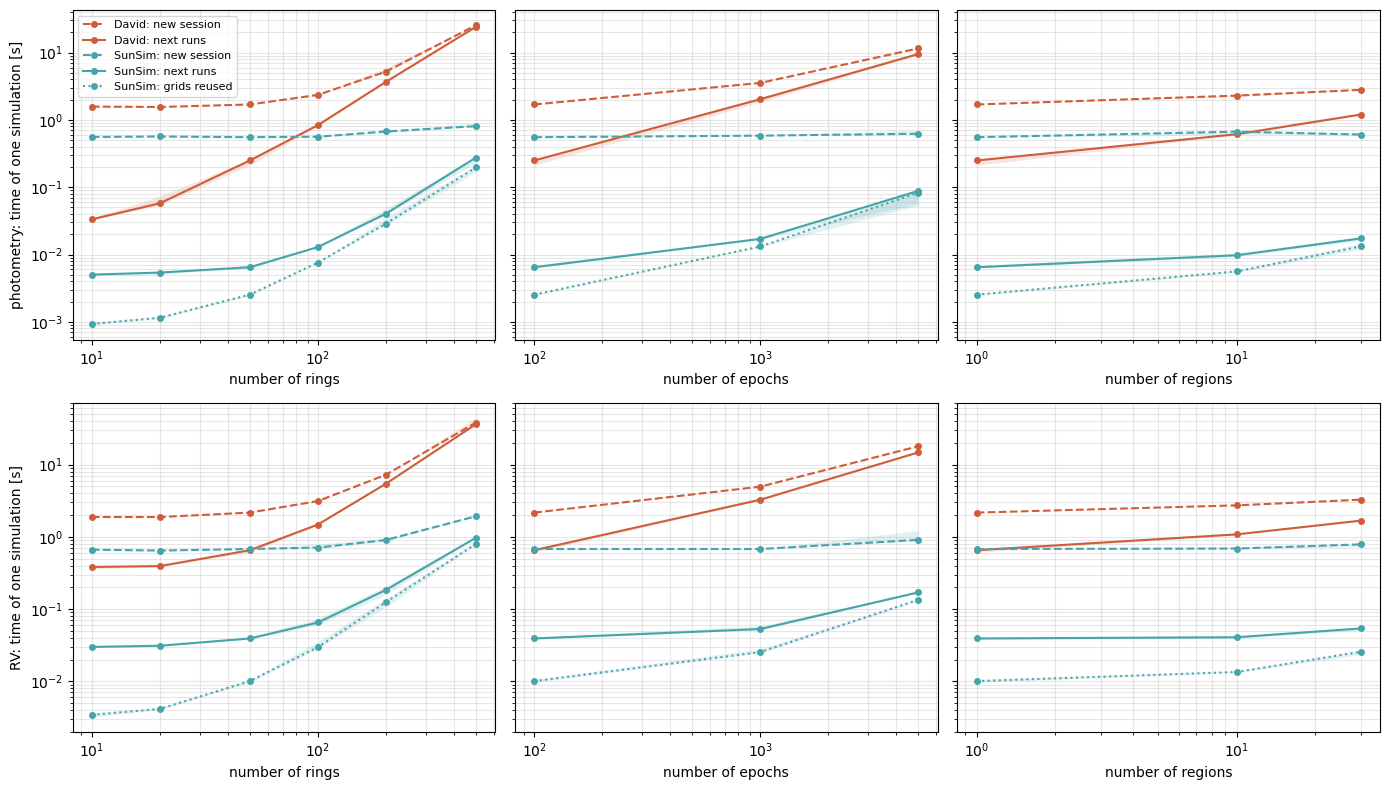

In [8]:
colors = {'David': '#cf5d3a', 'SunSim': '#45a5aa'}
labels = {'n_rings': 'number of rings', 'n_epochs': 'number of epochs', 'n_regions': 'number of regions'}

def sweep_rows(mode, key, version):
    others = [k for k in reference if k != key]
    d = summary[(summary['mode'] == mode) & (summary.version == version)
                & np.logical_and.reduce([summary[k] == reference[k] for k in others])]
    return d.sort_values(key)

fig, axes = plt.subplots(len(modes), 3, figsize=(14, 4 * len(modes)), sharey='row')
for i, mode in enumerate(modes):
    for j, key in enumerate(sweeps):
        ax = axes[i, j]
        for version in versions:
            d = sweep_rows(mode, key, version)
            series = [('new session [s]', '--o', 'new session'), ('next runs [s]', '-o', 'next runs')]
            if version == 'SunSim':
                series.append(('grids reused [s]', ':o', 'grids reused'))
            for col, style, name in series:
                ax.plot(d[key], d[col], style, color=colors[version], ms=4, label='%s: %s' % (version, name))
                ax.fill_between(d[key], d['q25 ' + col], d['q75 ' + col], color=colors[version], alpha=0.15, lw=0)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel(labels[key])
        ax.grid(alpha=0.3, which='both')
    axes[i, 0].set_ylabel('%s: time of one simulation [s]' % mode_names[mode])
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**The same with the `fast` mode of StarSim (D. Baroch)** (`simulation_mode = fast`, section 9: a loop over the regions instead
of the cells of the grid; its code says it only works for spots that do not overlap, which the random spots of `n_regions = 10, 30`
may do, so only its time is shown here). Every case of the sweeps, in `n_processes` new processes, against the `grid` mode and
SunSim of the runs above.

60 runs of the fast mode in 5.4 min


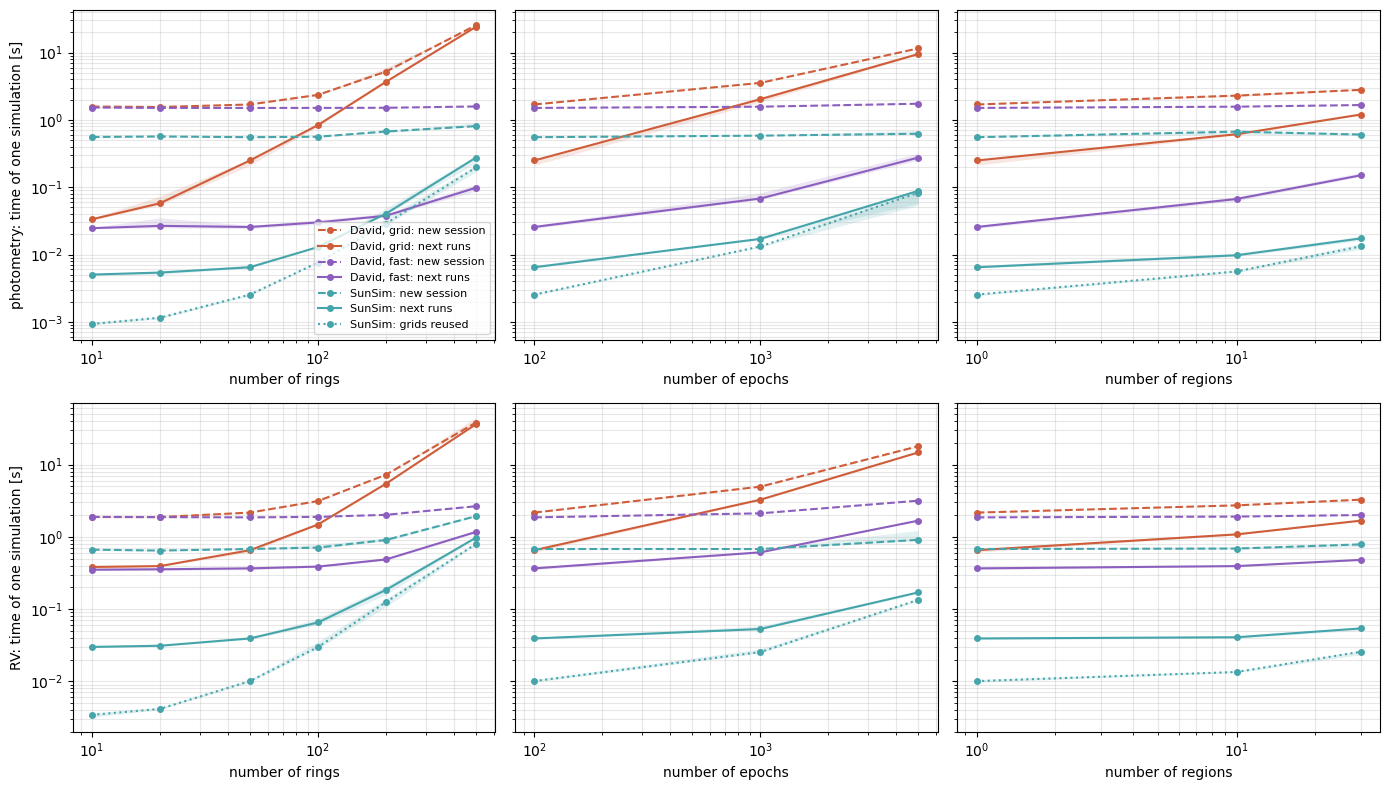

David grid [s]  David fast [s]  SunSim [s]  \
mode       parameter value                                               
photometry n_rings   10             0.0334          0.0246     0.00504   
                     20             0.0577          0.0267      0.0054   
                     50               0.25          0.0257     0.00648   
                     100             0.838            0.03      0.0129   
                     200              3.68          0.0377      0.0405   
                     500              24.1          0.0984       0.276   
           n_epochs  100              0.25          0.0257     0.00648   
                     1000             2.03           0.068      0.0171   
                     5000             9.52           0.276      0.0883   
           n_regions 1                0.25          0.0257     0.00648   
                     10              0.613           0.067     0.00976   
                     30                1.2            0.15      0.0174   
RV         n_rings   10              0.382            0.35      0.0299   
                     20              0.393           0.355       0.031   
                     50              0.652           0.365      0.0392   
                     100              1.48           0.386      0.0651   
                     200              5.42           0.486       0.184   
                     500              36.1            1.17       0.972   
           n_epochs  100             0.652           0.365      0.0392   
                     1000             3.26           0.609      0.0529   
                     5000             14.7            1.67        0.17   
           n_regions 1               0.652           0.365      0.0392   
                     10               1.08           0.393      0.0407   
                     30               1.67           0.478      0.0539   

                            SunSim grids reused [s]  grid / fast  \
mode       parameter value                                         
photometry n_rings   10                    0.000931         1.35   
                     20                     0.00115         2.16   
                     50                     0.00254         9.72   
                     100                    0.00761         27.9   
                     200                     0.0288         97.7   
                     500                      0.197          245   
           n_epochs  100                    0.00254         9.72   
                     1000                    0.0132         29.9   
                     5000                    0.0829         34.5   
           n_regions 1                      0.00254         9.72   
                     10                     0.00562         9.16   
                     30                      0.0132            8   
RV         n_rings   10                     0.00343         1.09   
                     20                     0.00415         1.11   
                     50                      0.0101         1.78   
                     100                     0.0297         3.82   
                     200                      0.125         11.2   
                     500                      0.796           31   
           n_epochs  100                     0.0101         1.78   
                     1000                    0.0254         5.36   
                     5000                     0.134         8.79   
           n_regions 1                       0.0101         1.78   
                     10                      0.0135         2.75   
                     30                      0.0256         3.49   

                            fast / SunSim  
mode       parameter value                 
photometry n_rings   10              4.89  
                     20              4.94  
                     50              3.97  
                     100             2.32  
                     200             0.93  
                     500  

In [9]:
sweep_fast = []
t0 = time.perf_counter()
for process in range(n_processes):
    for case in cases:
        for mode in modes:
            sweep_fast.append(run('David', mode, case, process=60 + process, tag='_fast', simulation_mode='fast'))
print('%d runs of the fast mode in %.1f min' % (len(sweep_fast), (time.perf_counter() - t0) / 60))
summary_fast = (pd.DataFrame([per_process(r) for r in sweep_fast]).groupby(keys, sort=False)[cold + ['next', 'reused']]
                .apply(aggregate).reset_index())
summary_fast['version'] = 'David, fast'
summary_all = pd.concat([summary, summary_fast], ignore_index=True)

colors_fast = {'David': colors['David'], 'David, fast': '#8c5fbf', 'SunSim': colors['SunSim']}
names_fast = {'David': 'David, grid', 'David, fast': 'David, fast', 'SunSim': 'SunSim'}

fig, axes = plt.subplots(len(modes), 3, figsize=(14, 4 * len(modes)), sharey='row')
for i, mode in enumerate(modes):
    for j, key in enumerate(sweeps):
        ax = axes[i, j]
        others = [k for k in reference if k != key]
        for version in colors_fast:
            d = summary_all[(summary_all['mode'] == mode) & (summary_all.version == version)
                            & np.logical_and.reduce([summary_all[k] == reference[k] for k in others])].sort_values(key)
            series = [('new session [s]', '--o', 'new session'), ('next runs [s]', '-o', 'next runs')]
            if version == 'SunSim':
                series.append(('grids reused [s]', ':o', 'grids reused'))
            for col, style, name in series:
                ax.plot(d[key], d[col], style, color=colors_fast[version], ms=4, label='%s: %s' % (names_fast[version], name))
                ax.fill_between(d[key], d['q25 ' + col], d['q75 ' + col], color=colors_fast[version], alpha=0.15, lw=0)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel(labels[key])
        ax.grid(alpha=0.3, which='both')
    axes[i, 0].set_ylabel('%s: time of one simulation [s]' % mode_names[mode])
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# next runs: David fast against David grid and SunSim, for every case of the sweeps
rows_f = []
for mode in modes:
    for key in sweeps:
        others = [k for k in reference if k != key]
        sel = lambda v: summary_all[(summary_all['mode'] == mode) & (summary_all.version == v)
                                    & np.logical_and.reduce([summary_all[k] == reference[k] for k in others])].set_index(key)
        g, f, s_ = sel('David'), sel('David, fast'), sel('SunSim')
        for v in g.index:
            rows_f.append({'mode': mode_names[mode], 'parameter': key, 'value': v,
                           'David grid [s]': g.loc[v, 'next runs [s]'], 'David fast [s]': f.loc[v, 'next runs [s]'],
                           'SunSim [s]': s_.loc[v, 'next runs [s]'], 'SunSim grids reused [s]': s_.loc[v, 'grids reused [s]'],
                           'grid / fast': g.loc[v, 'next runs [s]'] / f.loc[v, 'next runs [s]'],
                           'fast / SunSim': f.loc[v, 'next runs [s]'] / s_.loc[v, 'next runs [s]']})
pd.options.display.float_format = '{:.3g}'.format
pd.DataFrame(rows_f).set_index(['mode', 'parameter', 'value'])

Time of every step in the reference case: first repetition (median over the processes) and next repetitions (median of all).

In [10]:
def steps_table(case):
    groups = {}
    for r in runs:
        if any(r[k] != case[k] for k in case):
            continue
        for s in r['steps']:
            base, _, k = s['step'].rpartition(' ')
            if not k.isdigit():
                base, k = s['step'], '1'
            groups.setdefault((r['mode'], r['version'], base), []).append((int(k), s))
    rows = []
    for (mode, version, base), items in groups.items():
        first = [s for k, s in items if k == 1]
        nxt = [s for k, s in items if k > 1]
        rows.append({'mode': mode, 'version': version, 'step': base,
                     'first [s]': np.median([s['time [s]'] for s in first]),
                     'next (median) [s]': np.median([s['time [s]'] for s in nxt]) if nxt else np.nan,
                     'RAM of the step, first [MB]': np.median([s['rss peak [MB]'] - s['rss before [MB]'] for s in first])})
    return pd.DataFrame(rows).set_index(['mode', 'version', 'step'])

steps_table(reference)

first [s]  next (median) [s]  \
mode version step                                            
phot David   import                1.43                NaN   
             init               0.00274                NaN   
             compute_forward      0.249               0.25   
     SunSim  import               0.288                NaN   
             spectra             0.0198            0.00201   
             grids                 0.22            0.00197   
             simulation          0.0269            0.00254   
rv   David   import                1.46                NaN   
             init               0.00263                NaN   
             compute_forward       0.72              0.652   
     SunSim  import                 0.3                NaN   
             spectra              0.296             0.0176   
             grids               0.0345              0.011   
             simulation          0.0458             0.0101   

                              RAM of the step, first [MB]  
mode version step                                          
phot David   import                                   179  
             init                                   0.131  
             compute_forward                           32  
     SunSim  import                                  62.1  
             spectra                                 19.5  
             grids                                   40.8  
             simulation                              6.62  
rv   David   import                                   180  
             init                                  0.0492  
             compute_forward                          135  
     SunSim  import                                    62  
             spectra                                  105  
             grids                                   14.1  
             simulation                              29.7

## 5. RAM

Resident memory of the process: after the import, peak of the whole process (`ru_maxrss`), and their difference (memory of the
simulations), median over the processes.


PHOTOMETRY, n_rings


,David,SunSim,David,SunSim,David,SunSim
,RAM after import [MB],RAM after import [MB],RAM peak [MB],RAM peak [MB],RAM for the simulations [MB],RAM for the simulations [MB]
n_rings,,,,,,
10,216,98,301,192,85,93
20,216,98,301,191,85,92
50,216,99,284,197,69,98
100,216,99,304,208,88,109
200,217,99,342,264,125,165
500,217,99,603,575,387,475



PHOTOMETRY, n_epochs


,David,SunSim,David,SunSim,David,SunSim
,RAM after import [MB],RAM after import [MB],RAM peak [MB],RAM peak [MB],RAM for the simulations [MB],RAM for the simulations [MB]
n_epochs,,,,,,
100,216,99,284,197,69,98
1000,216,99,293,201,77,102
5000,216,99,293,205,76,105



PHOTOMETRY, n_regions


...

,David,SunSim,David,SunSim,David,SunSim
,RAM after import [MB],RAM after import [MB],RAM peak [MB],RAM peak [MB],RAM for the simulations [MB],RAM for the simulations [MB]
n_rings,,,,,,
10,217,99,423,344,207,246
20,216,99,415,381,200,282
50,217,98,410,420,194,322
100,215,99,513,471,298,372
200,215,100,779,775,564,675
500,217,99,2815,791,2596,693



RV, n_epochs


,David,SunSim,David,SunSim,David,SunSim
,RAM after import [MB],RAM after import [MB],RAM peak [MB],RAM peak [MB],RAM for the simulations [MB],RAM for the simulations [MB]
n_epochs,,,,,,
100,217,98,410,420,194,322
1000,218,99,422,408,205,309
5000,217,99,416,444,201,346



RV, n_regions


,David,SunSim,David,SunSim,David,SunSim
,RAM after import [MB],RAM after import [MB],RAM peak [MB],RAM peak [MB],RAM for the simulations [MB],RAM for the simulations [MB]
n_regions,,,,,,
1,217,98,410,420,194,322
10,216,99,441,380,225,281
30,216,99,418,405,201,305


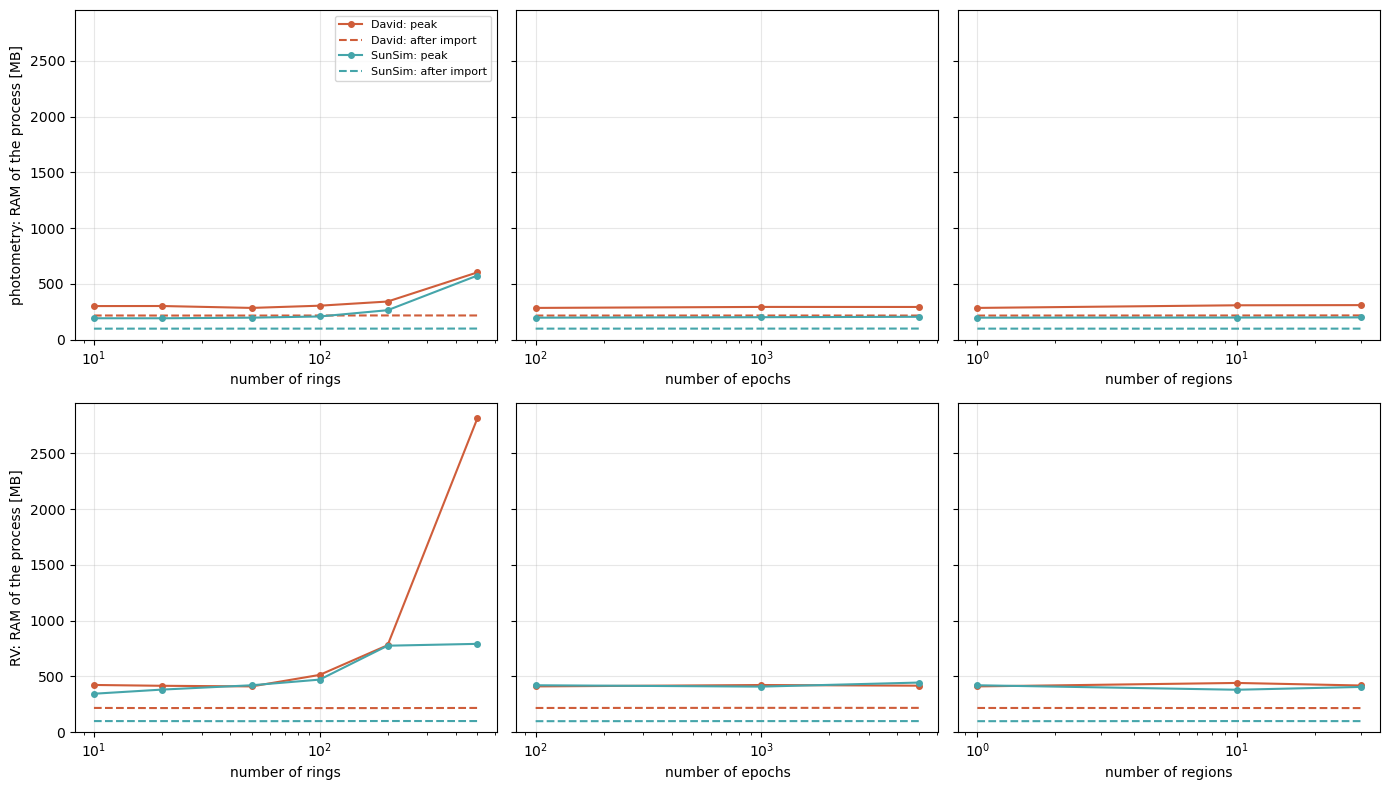

In [11]:
ram_columns = ['RAM after import [MB]', 'RAM peak [MB]', 'RAM for the simulations [MB]']
pd.options.display.float_format = '{:.0f}'.format
for mode in modes:
    for key in sweeps:
        print('\n%s, %s' % (mode_names[mode].upper(), key))
        display(side_by_side(mode, key, ram_columns))

fig, axes = plt.subplots(len(modes), 3, figsize=(14, 4 * len(modes)), sharey=True)
for i, mode in enumerate(modes):
    for j, key in enumerate(sweeps):
        ax = axes[i, j]
        for version in versions:
            d = sweep_rows(mode, key, version)
            ax.plot(d[key], d['RAM peak [MB]'], '-o', color=colors[version], ms=4, label='%s: peak' % version)
            ax.plot(d[key], d['RAM after import [MB]'], '--', color=colors[version], label='%s: after import' % version)
        ax.set_xscale('log')
        ax.set_xlabel(labels[key])
        ax.grid(alpha=0.3)
    axes[i, 0].set_ylabel('%s: RAM of the process [MB]' % mode_names[mode])
axes[0, 0].set_ylim(0, 1.05 * summary['RAM peak [MB]'].max())
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Outputs: reference case

The outputs of the two codes for the reference case (one spot of 8° with its facula of 16°, on the equator, one rotation), at
several numbers of rings. Photometry: flux / quiet star and filling factors [% of the disc]; RV: RV, FWHM and BIS (minus their
median), contrast / its median. The table gives the amplitude (max − min) of every output in both codes and the largest difference,
for SunSim (with the μ angles of StarSim (D. Baroch), known difference 6) and, for information, for SunSim with every Phoenix
model at its own μ (`own μ`), which shows the effect of these angles.

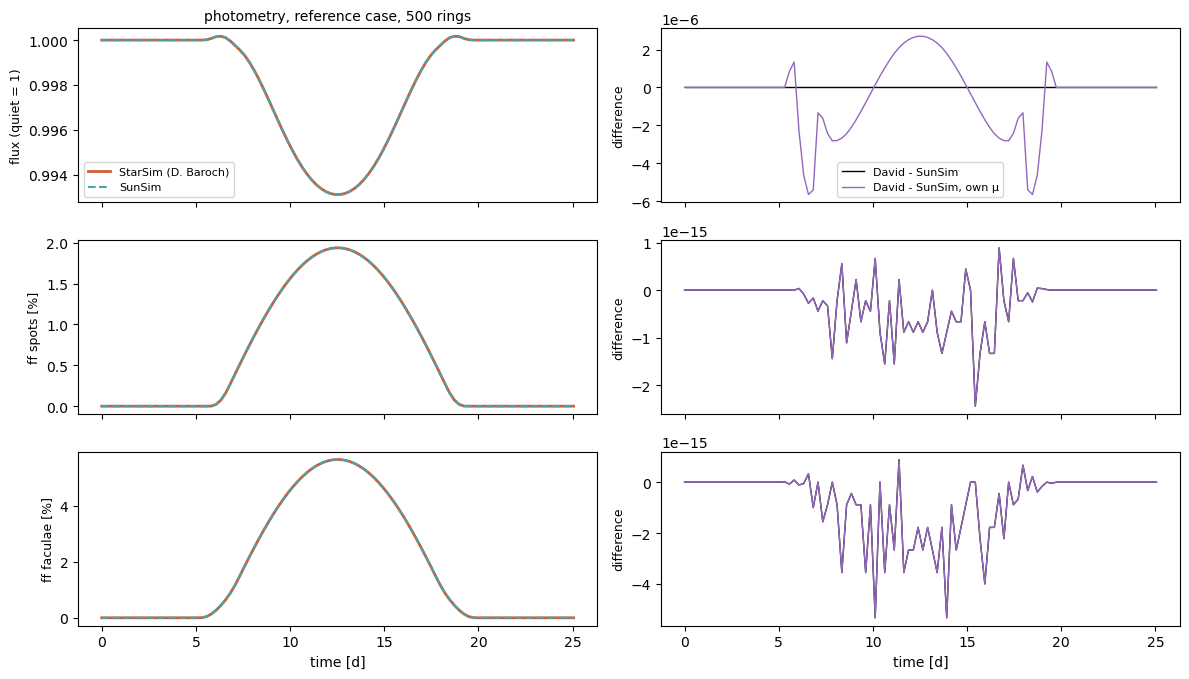

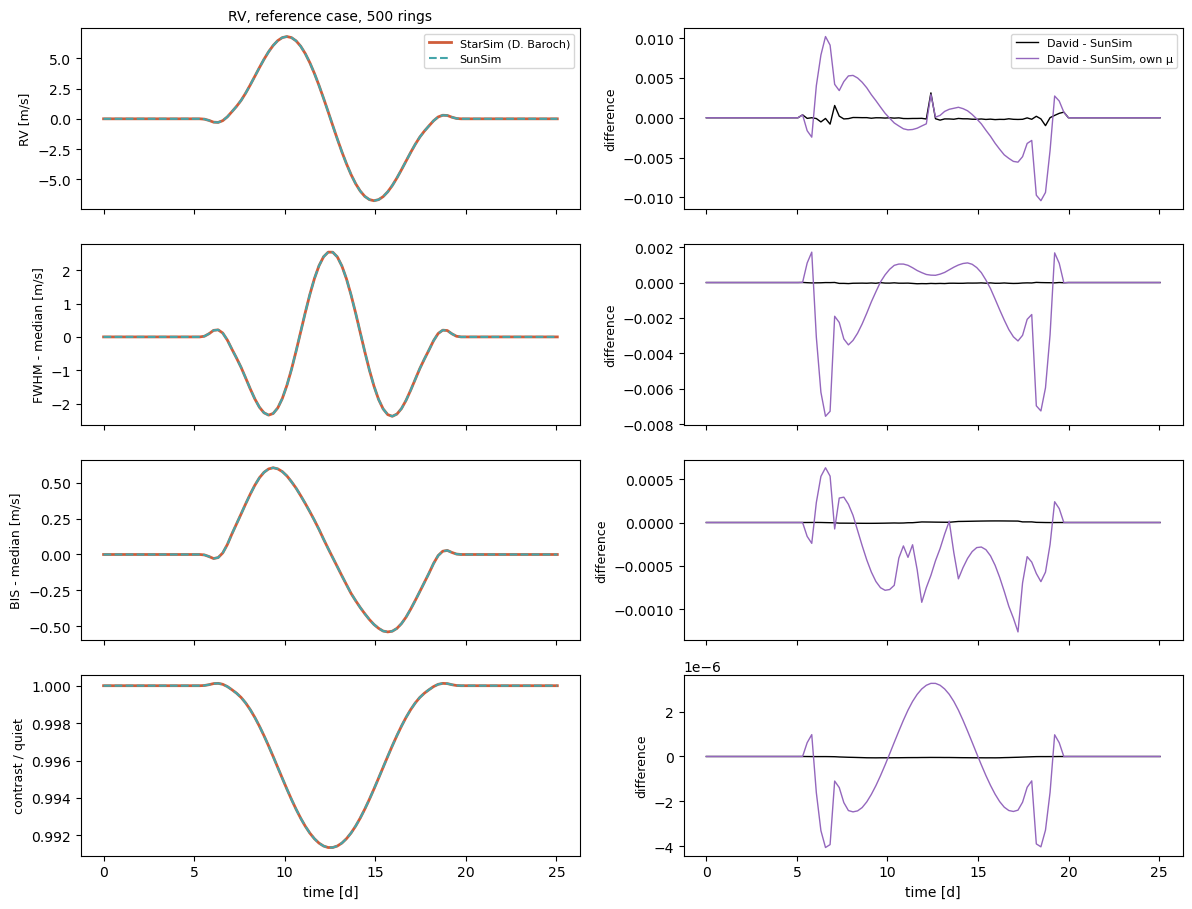

David (max - min)  SunSim (max - min)  \
quantity            rings                                          
BIS - median [m/s]  10                 1.195               1.195   
                    50                 1.142               1.142   
                    500                1.142               1.142   
FWHM - median [m/s] 10                 5.087               5.088   
                    50                 4.912               4.912   
                    500                4.916               4.916   
RV [m/s]            10                    13                  13   
                    50                 13.51               13.51   
                    500                13.55               13.55   
contrast / quiet    10               0.01005             0.01005   
                    50              0.008783            0.008783   
                    500             0.008774            0.008774   
ff faculae [%]      10                 5.733               5.733   
                    50                 5.661               5.661   
                    500                5.658               5.658   
ff spots [%]        10                 2.218               2.218   
                    50                 1.937               1.937   
                    500                1.936               1.936   
flux (quiet = 1)    10              0.008069            0.008069   
                    50              0.007066            0.007066   
                    500             0.007058            0.007058   

                           max |David - SunSim|  % of the amplitude  \
quantity            rings                                             
BIS - median [m/s]  10                 1.83e-05            0.001532   
                    50                1.815e-05            0.001589   
                    500               1.818e-05            0.001593   
FWHM - median [m/s] 10                8.108e-05            0.001594   
                    50                6.894e-05            0.001403   
                    500                 6.9e-05            0.001404   
RV [m/s]            10                 0.002074             0.01595   
                    50                 0.003819             0.02827   
                    500                0.003125             0.02306   
contrast / quiet    10                5.872e-08           0.0005843   
                    50                5.913e-08           0.0006732   
                    500               5.991e-08           0.0006828   
ff faculae [%]      10                1.776e-14           3.099e-13   
                    50                5.329e-15           9.414e-14   
                    500               5.329e-15           9.419e-14   
ff spots [%]        10                1.776e-14           8.007e-13   
                    50                4.885e-15           2.522e-13   
                    500               2.442e-15           1.262e-13   
flux (quiet = 1)    10                1.221e-15           1.514e-11   
                    50                8.327e-15           1.178e-10   
                    500               3.454e-13           4.893e-09   

                           max |David - SunSim, own μ|  \
quantity            rings                                
BIS - median [m/s]  10                       0.0006957   
                    50                        0.000762   
                    500                       0.001259   
FWHM - median [m/s] 10                        0.003509   
                    50                        0.003607   
                    500                       0.007562   
RV [m/s]            10                        0.005993   
                    50                        0.006041   
                    500                        0.01042   
contrast / quiet    10                       2.805e-06   
                    50                       2.581e-06   
                    500                      4.062e-06   
ff faculae [%]  

In [12]:
rows = {'phot': [('flux', 'flux (quiet = 1)', 'abs'), ('ff_sp', 'ff spots [%]', 'abs'), ('ff_fc', 'ff faculae [%]', 'abs')],
        'rv': [('rv', 'RV [m/s]', 'abs'), ('fwhm', 'FWHM - median [m/s]', 'median'),
               ('bis', 'BIS - median [m/s]', 'median'), ('contrast', 'contrast / quiet', 'abs')]}

def pick(source, mode, version, variant='', **match):
    return [r for r in source if r['mode'] == mode and r['version'] == version and 'outputs' in r
            and r.get('variant', '') == variant and all(r[k] == v for k, v in match.items())][0]['outputs']

def compared(a_out, b_out, key, how):
    a, b = np.asarray(a_out[key], dtype=float), np.asarray(b_out[key], dtype=float)
    if how == 'median':
        a, b = a - np.nanmedian(a), b - np.nanmedian(b)
    return a_out['times'], a, b

def diff_rows(a_out, b_out, mode, c_out=None, **label):
    """Amplitudes and largest differences: David (a_out) vs SunSim (b_out), and vs SunSim with every model at its own mu (c_out)."""
    out = []
    for key, name, how in rows[mode]:
        t, a, b = compared(a_out, b_out, key, how)
        amp = np.nanmax(a) - np.nanmin(a)
        d = np.nanmax(np.abs(a - b))
        row = dict(label, quantity=name, **{'David (max - min)': amp, 'SunSim (max - min)': np.nanmax(b) - np.nanmin(b),
                                          'max |David - SunSim|': d, '% of the amplitude': 100 * d / amp if amp else np.nan})
        if c_out is not None:
            dc = np.nanmax(np.abs(a - compared(a_out, c_out, key, how)[2]))
            row.update({"max |David - SunSim, own μ|": dc, "% of the amplitude, own μ": 100 * dc / amp if amp else np.nan})
        out.append(row)
    return out

def plot_pair(a_out, b_out, mode, title, c_out=None):
    fig, axes = plt.subplots(len(rows[mode]), 2, figsize=(12, 2.3 * len(rows[mode])), sharex=True, squeeze=False)
    for i, (key, name, how) in enumerate(rows[mode]):
        t, a, b = compared(a_out, b_out, key, how)
        axes[i, 0].plot(t, a, '-', lw=2, color=colors['David'], label='StarSim (D. Baroch)')
        axes[i, 0].plot(t, b, '--', lw=1.5, color=colors['SunSim'], label='SunSim')
        axes[i, 0].set_ylabel(name, fontsize=9)
        axes[i, 1].plot(t, a - b, '-', color='k', lw=1, label='David - SunSim')
        if c_out is not None:
            axes[i, 1].plot(t, a - compared(a_out, c_out, key, how)[2], '-', color='tab:purple', lw=1,
                            label="David - SunSim, own μ")
        axes[i, 1].set_ylabel('difference', fontsize=9)
    axes[0, 0].legend(fontsize=8)
    axes[0, 1].legend(fontsize=8)
    axes[0, 0].set_title(title, fontsize=10)
    axes[-1, 0].set_xlabel('time [d]')
    axes[-1, 1].set_xlabel('time [d]')
    plt.tight_layout()
    plt.show()

finest = max(output_rings)
for mode in modes:
    plot_pair(pick(output_runs, mode, 'David', n_rings=finest), pick(output_runs, mode, 'SunSim', n_rings=finest), mode,
              '%s, reference case, %d rings' % (mode_names[mode], finest),
              pick(output_runs, mode, 'SunSim', 'own_angles', n_rings=finest))

table = []
for n in output_rings:
    for mode in modes:
        table += diff_rows(pick(output_runs, mode, 'David', n_rings=n), pick(output_runs, mode, 'SunSim', n_rings=n), mode,
                           pick(output_runs, mode, 'SunSim', 'own_angles', n_rings=n), rings=n)
pd.options.display.float_format = '{:.4g}'.format
reference_diffs = pd.DataFrame(table).set_index(['quantity', 'rings']).sort_index(level=[0, 1], sort_remaining=False)
reference_diffs

## 7. Comparison of the CCFs

The CCF of the whole disc at the first epoch and at the epoch of the largest RV, in both codes (normalised to its maximum), and their
difference: the two codes integrate the same ring CCFs; the differences in the CCF parameters come from the fit and the zero points.

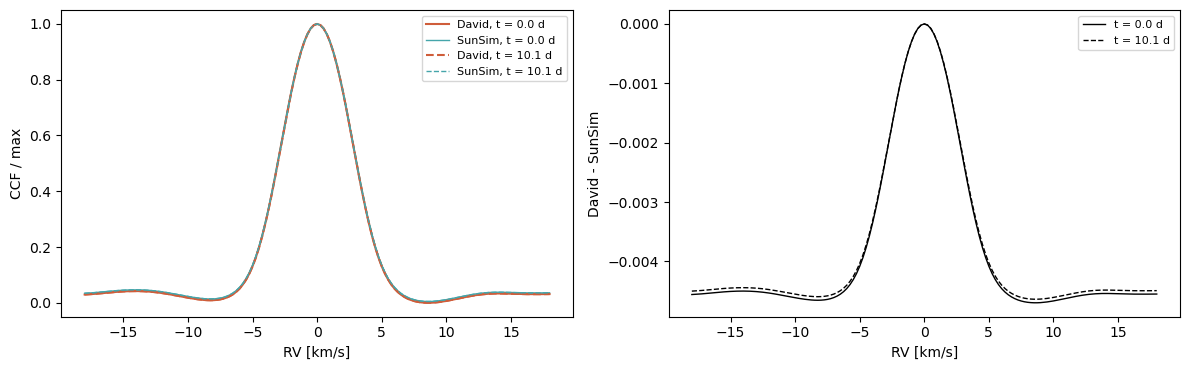

velocity grids identical: True


In [13]:
a_out, b_out = pick(output_runs, 'rv', 'David', n_rings=finest), pick(output_runs, 'rv', 'SunSim', n_rings=finest)
k_max = int(np.nanargmax(np.abs(a_out['rv'])))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for k, style in ((0, '-'), (k_max, '--')):
    ca = a_out['ccf'][k] / a_out['ccf'][k].max()
    cb = np.interp(a_out['ccf_rv'], b_out['ccf_rv'], b_out['ccf'][k]) / b_out['ccf'][k].max()
    axes[0].plot(a_out['ccf_rv'] / 1000, ca, style, color=colors['David'], label='David, t = %.1f d' % a_out['times'][k])
    axes[0].plot(b_out['ccf_rv'] / 1000, b_out['ccf'][k] / b_out['ccf'][k].max(), style, color=colors['SunSim'], lw=1,
                 label='SunSim, t = %.1f d' % a_out['times'][k])
    axes[1].plot(a_out['ccf_rv'] / 1000, ca - cb, style, color='k', lw=1, label='t = %.1f d' % a_out['times'][k])
axes[0].set_xlabel('RV [km/s]'); axes[0].set_ylabel('CCF / max'); axes[0].legend(fontsize=8)
axes[1].set_xlabel('RV [km/s]'); axes[1].set_ylabel('David - SunSim'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print('velocity grids identical:', np.allclose(a_out['ccf_rv'], b_out['ccf_rv']))

## 8. Special cases

Every case is one run of each code (not timed), on `special_rings` rings, in the modes listed; SunSim runs twice, as it is (the μ angles
of StarSim (D. Baroch)) and with every Phoenix model at its own μ (`own μ`, for information). All the other settings are
those of the reference.

| case | what is tested |
|---|---|
| `spot alone` | Q = 0: no facula |
| `spot + facula` | the reference (Q = 3) |
| `three spots` | three spots and their faculae, one crossing the centre of the disc (known difference 1, photometry) |
| `facula alone` | a facula of 16° around a spot of 0.1° with ΔT = 0 (the spectrum of the quiet photosphere) |
| `inclination 60°` | the star seen at 60° (StarSim convention: 90 = equator-on) |
| `growing spot` | `spots_evo_law = linear`: radius from 2° to 12° over the rotation |
| `differential rotation` | B = −2.66 °/day, spot at latitude +45° (known difference 3: RV) |
| `convective shift` | CB = 1: CIFIST bisector for the photosphere, Dumusque for the spot and the facula |
| `planet (ramp)` | a transit (Rp = 0.1 R*, b = 0.3, K = 10 m/s), SunSim with the planet coverage of StarSim (D. Baroch) |
| `planet (exact area)` | the same, SunSim with its default exact coverage (known difference 4) |

In [14]:
special_rings = 50
P = star['P_rot']
transit = dict(planet=dict(period=3.0, t0=1.0, radius=0.1, b=0.3, K=10.0), t_range=[0.85, 1.15], n_epochs=150,
               regions=[[90.0, 300.0, 8.0]])     # the spot on the far side during the transit
special_cases = {
    'spot alone': (['phot', 'rv'], dict(Q=0.0)),
    'spot + facula': (['phot', 'rv'], dict()),
    'three spots': (['phot', 'rv'], dict(regions=[[90.0, 180.0, 8.0], [60.0, 60.0, 5.0], [120.0, 300.0, 4.0]])),
    'facula alone': (['phot', 'rv'], dict(Q=(16.0 / 0.1)**2 - 1, dT_spot=0.0, regions=[[90.0, 180.0, 0.1]])),
    'inclination 60°': (['phot', 'rv'], dict(inclination=60.0, regions=[[60.0, 180.0, 8.0]])),
    'growing spot': (['phot', 'rv'], dict(evo_law='linear', spot_rows=[[0.0, P, 90.0, 180.0, 2.0, 12.0, 0.0]])),
    'differential rotation': (['phot', 'rv'], dict(B=-2.66, regions=[[45.0, 180.0, 8.0]], t_range=[0.0, 2 * P], n_epochs=200)),
    'convective shift': (['rv'], dict(CB=1.0)),
    'planet (ramp)': (['phot', 'rv'], dict(transit)),
    'planet (exact area)': (['phot', 'rv'], dict(transit, planet_coverage='area')),
}
special = {}
t0 = time.perf_counter()
for name, (case_modes, override) in special_cases.items():
    override = dict(override)
    n_epochs = override.pop('n_epochs', reference['n_epochs'])
    case = dict(reference, n_rings=special_rings, n_epochs=n_epochs)
    for mode in case_modes:
        for version in versions:
            # StarSim (D. Baroch) has a single planet coverage: its run of the 'exact area' case is the 'ramp' one
            o = dict(override, planet_coverage='ramp') if version == 'David' else override
            r = run(version, mode, case, process=50, keep_outputs=True, n_next=0, min_next=0,
                    tag='_' + ''.join(ch for ch in name if ch.isalnum()), **o)
            special[(name, mode, version)] = r['outputs']
        r = run('SunSim', mode, case, process=50, keep_outputs=True, n_next=0, min_next=0, own_angles=True,
                tag='_ownangles_' + ''.join(ch for ch in name if ch.isalnum()), **override)
        special[(name, mode, 'SunSim angles')] = r['outputs']
print('special cases: %d runs in %.1f min' % (len(special), (time.perf_counter() - t0) / 60))

table = []
for name, (case_modes, _) in special_cases.items():
    for mode in case_modes:
        table += diff_rows(special[(name, mode, 'David')], special[(name, mode, 'SunSim')], mode,
                           special[(name, mode, 'SunSim angles')], case=name, observable=mode_names[mode])
special_diffs = pd.DataFrame(table).set_index(['case', 'observable', 'quantity'])
pd.options.display.float_format = '{:.4g}'.format
pd.options.display.max_rows = 200
special_diffs

special cases: 57 runs in 1.4 min


David (max - min)  \
case                  observable quantity                                 
spot alone            photometry flux (quiet = 1)              0.007137   
                                 ff spots [%]                     1.937   
                                 ff faculae [%]                       0   
                      RV         RV [m/s]                          15.2   
                                 FWHM - median [m/s]              4.985   
                                 BIS - median [m/s]               1.964   
                                 contrast / quiet              0.008984   
spot + facula         photometry flux (quiet = 1)              0.007066   
                                 ff spots [%]                     1.937   
                                 ff faculae [%]                   5.661   
                      RV         RV [m/s]                         13.51   
                                 FWHM - median [m/s]              4.912   
                                 BIS - median [m/s]               1.142   
                                 contrast / quiet              0.008783   
three spots           photometry flux (quiet = 1)              0.006202   
                                 ff spots [%]                     1.557   
                                 ff faculae [%]                   4.499   
                      RV         RV [m/s]                          13.6   
                                 FWHM - median [m/s]              5.063   
                                 BIS - median [m/s]               1.058   
                                 contrast / quiet              0.007901   
facula alone          photometry flux (quiet = 1)              0.001455   
                                 ff spots [%]                 0.0003035   
                                 ff faculae [%]                   7.598   
                      RV         RV [m/s]                          4.94   
                                 FWHM - median [m/s]              1.528   
                                 BIS - median [m/s]               1.259   
                                 contrast / quiet              0.001223   
inclination 60°       photometry flux (quiet = 1)              0.007084   
                                 ff spots [%]                     1.942   
                                 ff faculae [%]                   5.656   
                      RV         RV [m/s]                         11.32   
                                 FWHM - median [m/s]              3.179   
                                 BIS - median [m/s]               1.438   
                                 contrast / quiet              0.008682   
growing spot          photometry flux (quiet = 1)              0.005873   
                                 ff spots [%]                     1.621   
                                 ff faculae [%]                   4.773   
                      RV         RV [m/s]                         10.74   
                                 FWHM - median [m/s]              4.584   
                                 BIS - median [m/s]              0.8877   
                                 contrast / quiet               0.00712   
differential rotation photometry flux (quiet = 1)              0.003831   
                                 ff spots [%]                     1.369   
                                 ff faculae [%]                       4   
                      RV         RV [m/s]                         4.444   
                                 FWHM - median [m/s]              1.501   
                                 BIS - median [m/s]               0.473   
                                 contrast / quiet              0.004697   
convective shift      RV         RV [m/s]                         34.68   
                                 FWHM - median [m/s]              44.08   
                                 BIS - median [m/s]               5.658   
    

The cases with a known difference, in time:

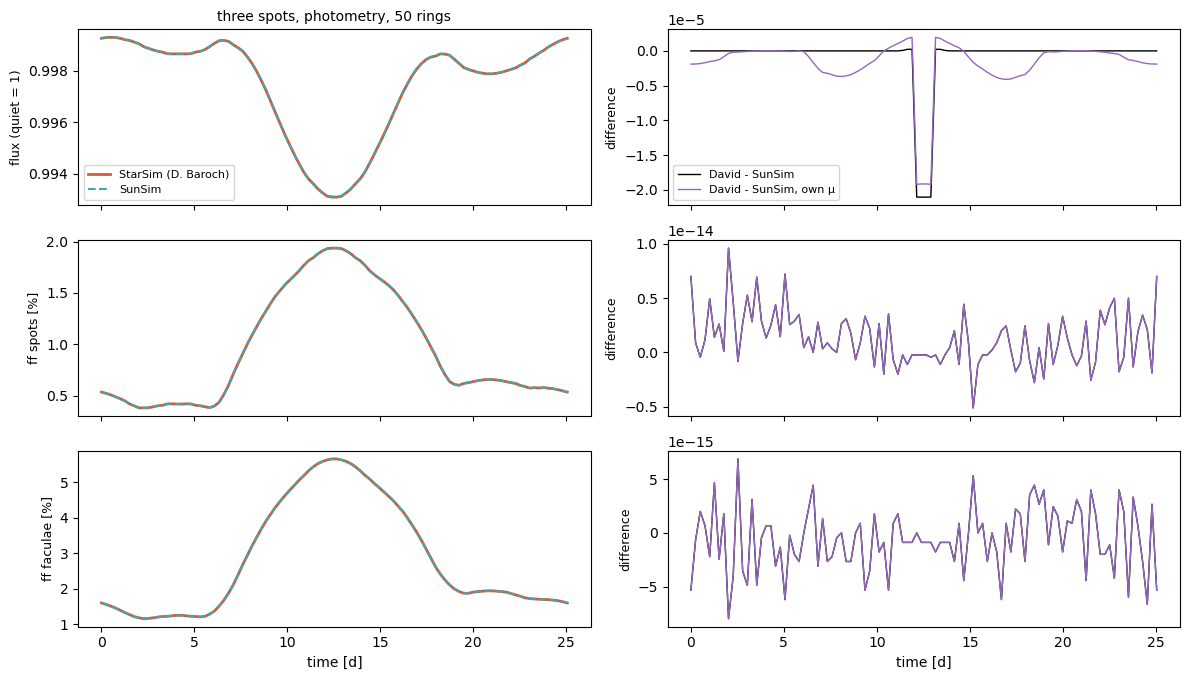

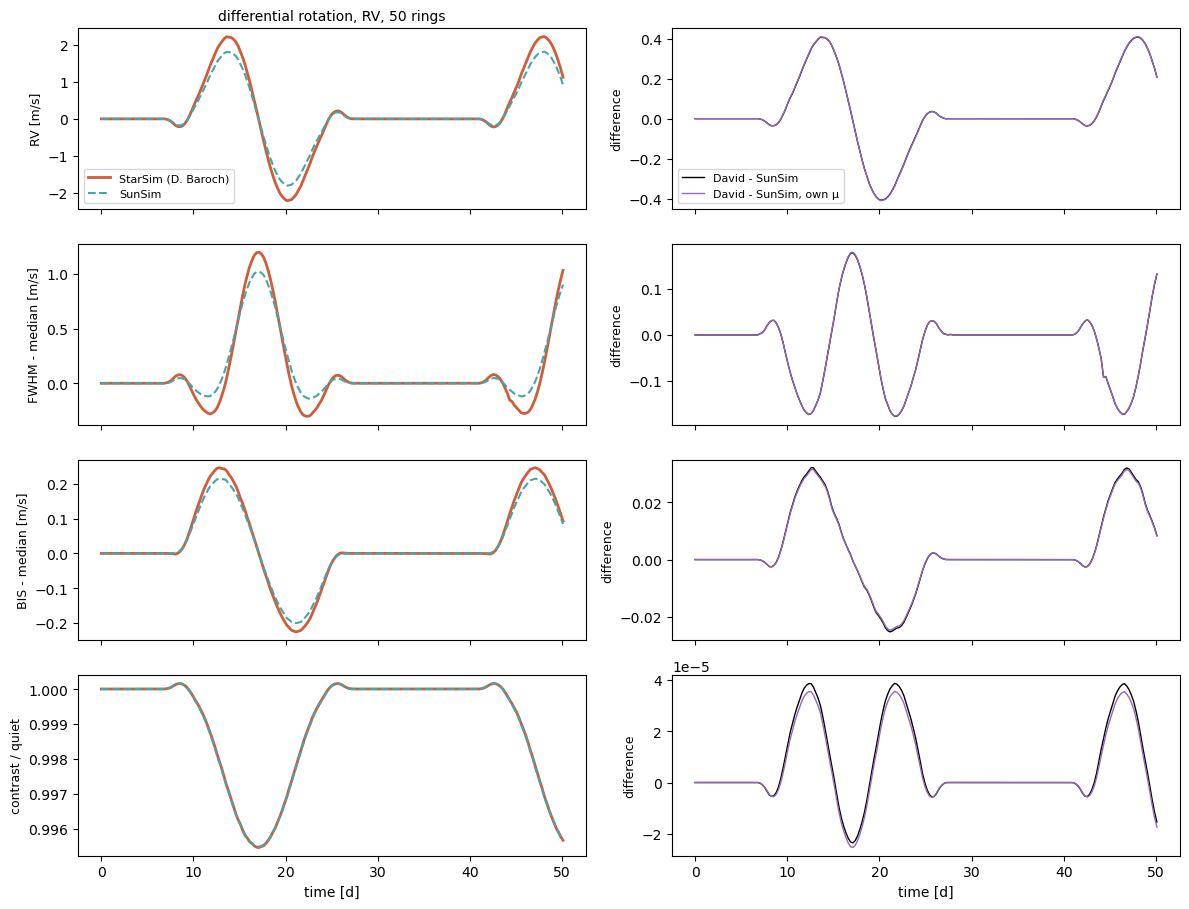

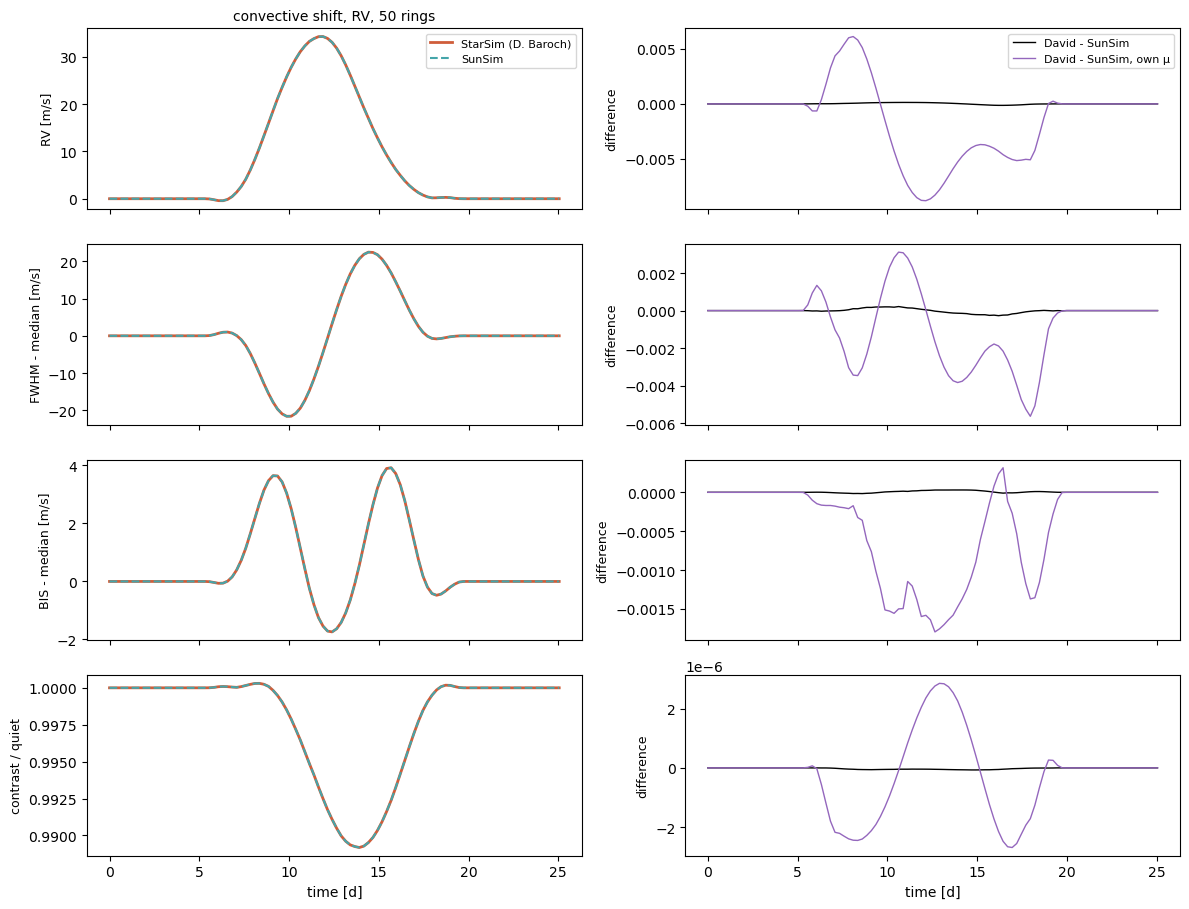

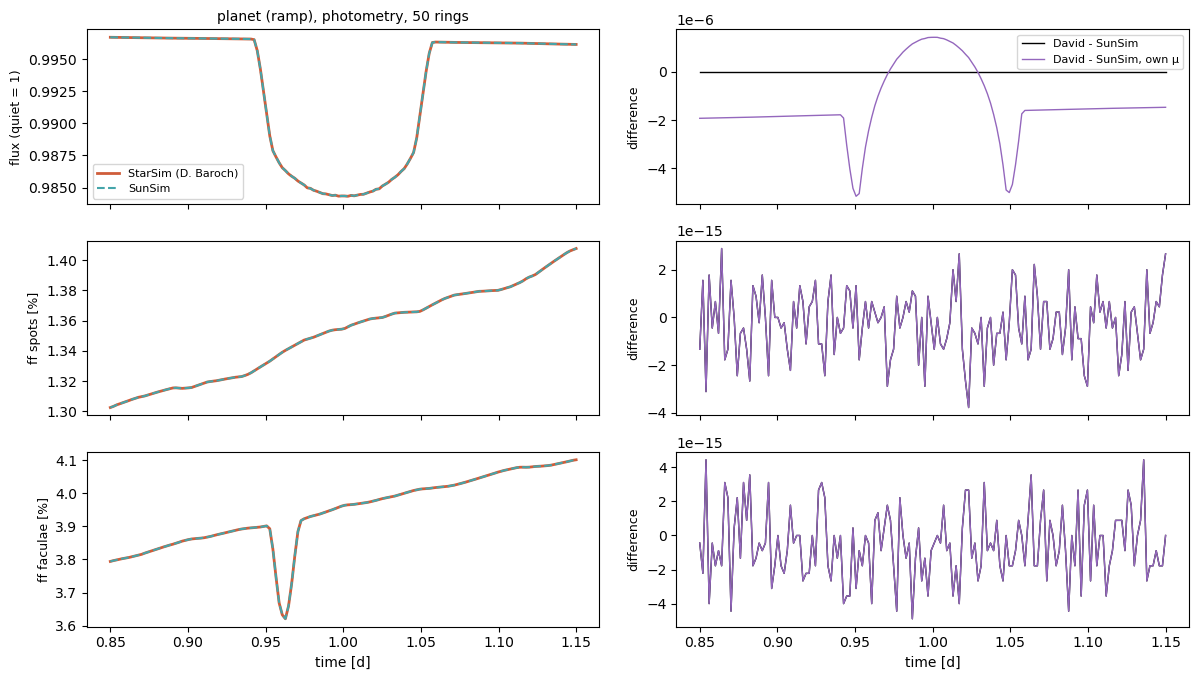

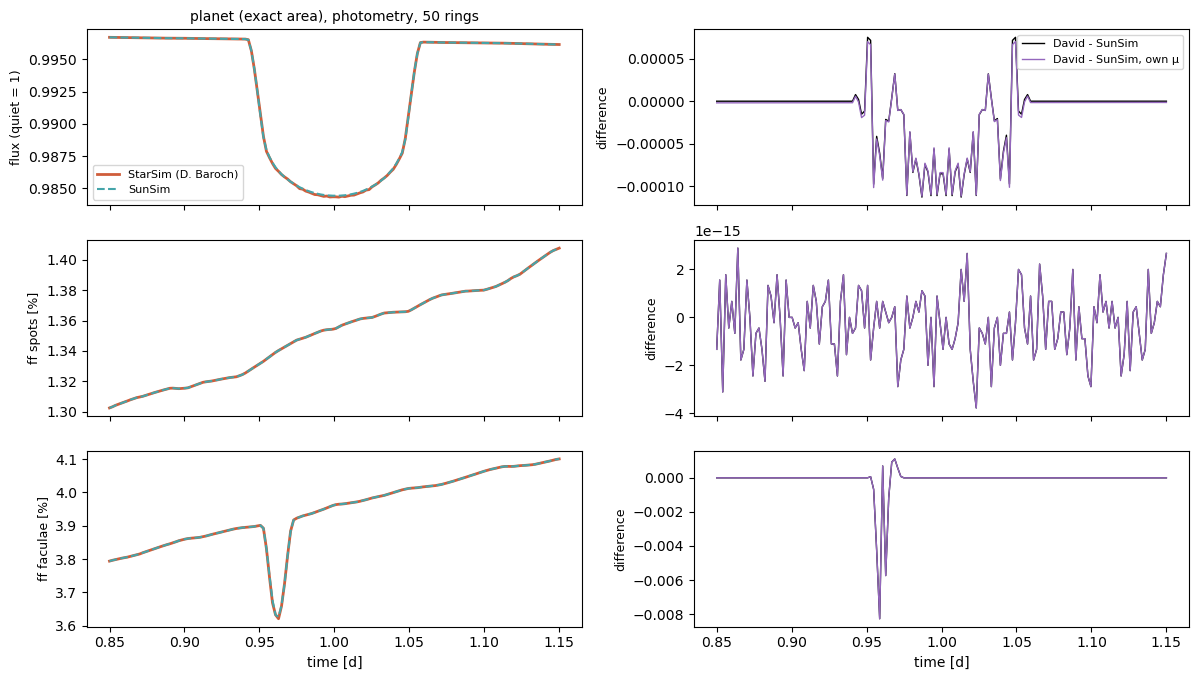

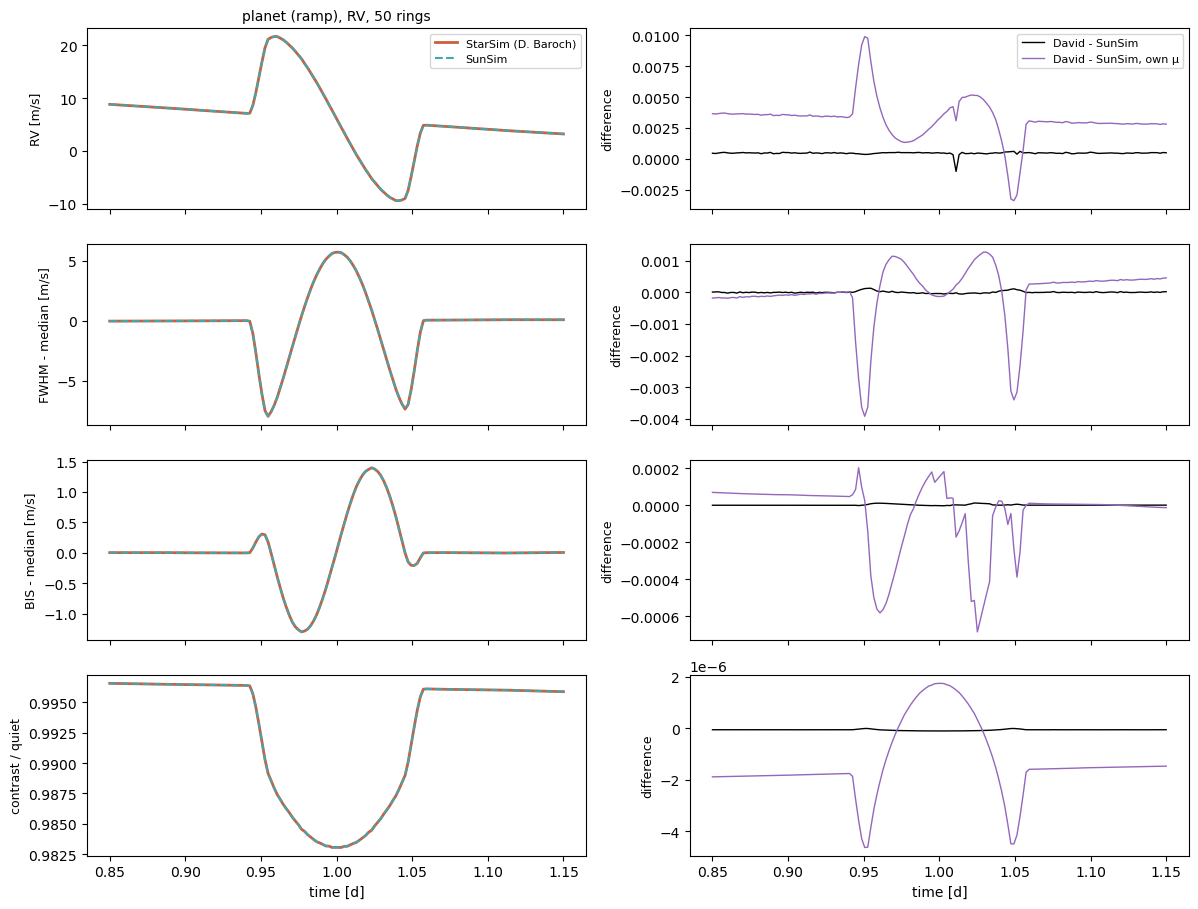

In [15]:
for name, mode in [('three spots', 'phot'), ('differential rotation', 'rv'), ('convective shift', 'rv'),
                   ('planet (ramp)', 'phot'), ('planet (exact area)', 'phot'), ('planet (ramp)', 'rv')]:
    plot_pair(special[(name, mode, 'David')], special[(name, mode, 'SunSim')], mode, '%s, %s, %d rings' % (name, mode_names[mode], special_rings),
              special[(name, mode, 'SunSim angles')])

## 9. The `fast` mode of StarSim (D. Baroch)

StarSim (D. Baroch) has a second mode, `simulation_mode = fast`, which loops over the spots instead of the cells of the grid (its code
says it only works for non-overlapping spots). SunSim has a single mode. Here the reference case (one spot + facula) and the spot
alone: time (median of `n_processes` processes) and outputs of the `fast` and `grid` modes, against SunSim.

In [16]:
fast_runs = []
for process in range(n_processes):
    for mode in modes:
        for sim_mode in ('fast', 'grid'):
            r = run('David', mode, reference, process=70 + process, keep_outputs=(process == 0), tag='_' + sim_mode,
                    simulation_mode=sim_mode)
            r['simulation_mode'] = sim_mode
            fast_runs.append(r)
rows_t = []
for mode in modes:
    for sim_mode in ('fast', 'grid'):
        pp = [per_process(r) for r in fast_runs if r['mode'] == mode and r['simulation_mode'] == sim_mode]
        rows_t.append({'mode': mode_names[mode], 'version': 'David, %s' % sim_mode,
                       'new session [s]': np.median([p['new session [s]'] for p in pp]),
                       'next runs [s]': np.median(np.concatenate([p['next'] for p in pp]))})
    s = summary[(summary['mode'] == mode) & (summary.version == 'SunSim')
                & np.logical_and.reduce([summary[k] == reference[k] for k in reference])].iloc[0]
    rows_t.append({'mode': mode_names[mode], 'version': 'SunSim', 'new session [s]': s['new session [s]'],
                   'next runs [s]': s['next runs [s]'], 'grids reused [s]': s['grids reused [s]']})
pd.options.display.float_format = '{:.3g}'.format
display(pd.DataFrame(rows_t).set_index(['mode', 'version']))

table = []
for mode in modes:
    fast = [r for r in fast_runs if r['mode'] == mode and r['simulation_mode'] == 'fast' and 'outputs' in r][0]['outputs']
    grid = [r for r in fast_runs if r['mode'] == mode and r['simulation_mode'] == 'grid' and 'outputs' in r][0]['outputs']
    sun = pick(runs, mode, 'SunSim', **reference)
    for key, name, how in rows[mode]:
        _, f, g = compared(fast, grid, key, how)
        _, _, s_ = compared(fast, sun, key, how)
        amp = np.nanmax(g) - np.nanmin(g)
        table.append({'mode': mode_names[mode], 'quantity': name, 'David grid (max - min)': amp,
                      'max |fast - grid|': np.nanmax(np.abs(f - g)), 'max |grid - SunSim|': np.nanmax(np.abs(g - s_)),
                      'max |fast - SunSim|': np.nanmax(np.abs(f - s_))})
pd.options.display.float_format = '{:.4g}'.format
pd.DataFrame(table).set_index(['mode', 'quantity'])

new session [s]  next runs [s]  grids reused [s]
mode       version                                                      
photometry David, fast             1.54         0.0259               NaN
           David, grid             1.72          0.238               NaN
           SunSim                 0.554        0.00648           0.00254
RV         David, fast             1.88          0.363               NaN
           David, grid             2.11          0.627               NaN
           SunSim                 0.677         0.0392            0.0101

David grid (max - min)  max |fast - grid|  \
mode       quantity                                                         
photometry flux (quiet = 1)                   0.007066          0.0005088   
           ff spots [%]                          1.937            0.01521   
           ff faculae [%]                        5.661           0.008293   
RV         RV [m/s]                              13.51              0.325   
           FWHM - median [m/s]                   4.912             0.2609   
           BIS - median [m/s]                    1.142            0.07082   
           contrast / quiet                   0.008783          0.0001764   

                                max |grid - SunSim|  max |fast - SunSim|  
mode       quantity                                                       
photometry flux (quiet = 1)               8.327e-15            0.0005088  
           ff spots [%]                   4.885e-15              0.01521  
           ff faculae [%]                 5.329e-15             0.008293  
RV         RV [m/s]                        0.003819               0.3255  
           FWHM - median [m/s]            6.894e-05               0.2609  
           BIS - median [m/s]             1.815e-05              0.07081  
           contrast / quiet               5.913e-08            0.0001764

**The same at 500 rings.** The reference case (one spot + facula, 100 epochs) on a grid of 500 rings instead of 50: time
(median of `n_processes` processes) and outputs of the `fast` and `grid` modes of StarSim (D. Baroch) and of SunSim.

In [17]:
case_big = dict(reference, n_rings=500)
fast_runs_big = []
for process in range(n_processes):
    for mode in modes:
        for sim_mode in ('fast', 'grid'):
            r = run('David', mode, case_big, process=80 + process, keep_outputs=(process == 0), tag='_' + sim_mode,
                    simulation_mode=sim_mode)
            r['simulation_mode'] = sim_mode
            fast_runs_big.append(r)
        r = run('SunSim', mode, case_big, process=80 + process, keep_outputs=(process == 0))
        r['simulation_mode'] = 'SunSim'
        fast_runs_big.append(r)

rows_t = []
for mode in modes:
    for sim_mode, version in (('fast', 'David, fast'), ('grid', 'David, grid'), ('SunSim', 'SunSim')):
        pp = [per_process(r) for r in fast_runs_big if r['mode'] == mode and r['simulation_mode'] == sim_mode]
        reused = np.concatenate([p['reused'] for p in pp])
        rows_t.append({'mode': mode_names[mode], 'version': version,
                       'new session [s]': np.median([p['new session [s]'] for p in pp]),
                       'next runs [s]': np.median(np.concatenate([p['next'] for p in pp])),
                       'grids reused [s]': np.median(reused) if len(reused) else np.nan})
pd.options.display.float_format = '{:.3g}'.format
display(pd.DataFrame(rows_t).set_index(['mode', 'version']))

def outputs_big(mode, sim_mode):
    return [r for r in fast_runs_big if r['mode'] == mode and r['simulation_mode'] == sim_mode and 'outputs' in r][0]['outputs']

table = []
for mode in modes:
    fast, grid, sun = outputs_big(mode, 'fast'), outputs_big(mode, 'grid'), outputs_big(mode, 'SunSim')
    for key, name, how in rows[mode]:
        _, f, g = compared(fast, grid, key, how)
        _, _, s_ = compared(fast, sun, key, how)
        amp = np.nanmax(g) - np.nanmin(g)
        table.append({'mode': mode_names[mode], 'quantity': name, 'David grid (max - min)': amp,
                      'max |fast - grid|': np.nanmax(np.abs(f - g)), 'max |grid - SunSim|': np.nanmax(np.abs(g - s_)),
                      'max |fast - SunSim|': np.nanmax(np.abs(f - s_))})
pd.options.display.float_format = '{:.4g}'.format
pd.DataFrame(table).set_index(['mode', 'quantity'])

new session [s]  next runs [s]  grids reused [s]
mode       version                                                      
photometry David, fast             1.64         0.0834               NaN
           David, grid               25           23.9               NaN
           SunSim                 0.828          0.234             0.171
RV         David, fast             2.74           1.13               NaN
           David, grid             37.8           34.9               NaN
           SunSim                  1.76           0.87             0.708

David grid (max - min)  max |fast - grid|  \
mode       quantity                                                         
photometry flux (quiet = 1)                   0.007058          0.0005117   
           ff spots [%]                          1.936          0.0001841   
           ff faculae [%]                        5.658          0.0002579   
RV         RV [m/s]                              13.55             0.3072   
           FWHM - median [m/s]                   4.916             0.2545   
           BIS - median [m/s]                    1.142            0.06637   
           contrast / quiet                   0.008774           0.000124   

                                max |grid - SunSim|  max |fast - SunSim|  
mode       quantity                                                       
photometry flux (quiet = 1)               3.454e-13            0.0005117  
           ff spots [%]                   2.442e-15            0.0001841  
           ff faculae [%]                 5.329e-15            0.0002579  
RV         RV [m/s]                        0.003125               0.3072  
           FWHM - median [m/s]              6.9e-05               0.2545  
           BIS - median [m/s]             1.818e-05              0.06636  
           contrast / quiet               5.991e-08            0.0001241

## 10. Summary

The numbers below are computed from the runs above (reference case: 50 rings, 100 epochs, one spot + facula).

In [18]:
ref = summary[np.logical_and.reduce([summary[k] == reference[k] for k in reference])].set_index(['mode', 'version'])
lines = []
for mode in modes:
    s_ = ref.loc[(mode, 'SunSim')]
    pp = {sim_mode: [per_process(r) for r in fast_runs if r['mode'] == mode and r['simulation_mode'] == sim_mode]
          for sim_mode in ('grid', 'fast')}
    david = {sim_mode: {'new session [s]': np.median([p['new session [s]'] for p in pp[sim_mode]]),
                        'next run [s]': np.median(np.concatenate([p['next'] for p in pp[sim_mode]])),
                        'RAM peak [MB]': np.median([p['RAM peak [MB]'] for p in pp[sim_mode]])}
             for sim_mode in pp}
    versions_t = [('David, grid', david['grid']), ('David, fast', david['fast']),
                  ('SunSim', {'new session [s]': s_['new session [s]'], 'next run [s]': s_['next runs [s]'],
                              'RAM peak [MB]': s_['RAM peak [MB]']}),
                  ('SunSim, grids reused', {'new session [s]': np.nan, 'next run [s]': s_['grids reused [s]'],
                                            'RAM peak [MB]': np.nan})]
    for version, v in versions_t:
        lines.append({'mode': mode_names[mode], 'version': version, **v,
                      'speed-up vs David grid (new session)': david['grid']['new session [s]'] / v['new session [s]'],
                      'speed-up vs David grid (next run)': david['grid']['next run [s]'] / v['next run [s]']})
pd.options.display.float_format = '{:.3g}'.format
display(pd.DataFrame(lines).set_index(['mode', 'version']))
worst = reference_diffs.reset_index()
worst = worst[worst.rings == finest][['quantity', 'David (max - min)', 'max |David - SunSim|', '% of the amplitude',
                                      "max |David - SunSim, own μ|", "% of the amplitude, own μ"]]
print('Outputs, reference case, %d rings:' % finest)
display(worst.set_index('quantity'))

new session [s]  next run [s]  RAM peak [MB]  \
mode       version                                                              
photometry David, grid                      1.72         0.238            324   
           David, fast                      1.54        0.0259            299   
           SunSim                          0.554       0.00648            197   
           SunSim, grids reused              NaN       0.00254            NaN   
RV         David, grid                      2.11         0.627            421   
           David, fast                      1.88         0.363            434   
           SunSim                          0.677        0.0392            420   
           SunSim, grids reused              NaN        0.0101            NaN   

                                 speed-up vs David grid (new session)  \
mode       version                                                      
photometry David, grid                                              1   
           David, fast                                           1.12   
           SunSim                                                 3.1   
           SunSim, grids reused                                   NaN   
RV         David, grid                                              1   
           David, fast                                           1.12   
           SunSim                                                3.12   
           SunSim, grids reused                                   NaN   

                                 speed-up vs David grid (next run)  
mode       version                                                  
photometry David, grid                                           1  
           David, fast                                        9.22  
           SunSim                                             36.8  
           SunSim, grids reused                               93.8  
RV         David, grid                                           1  
           David, fast                                        1.72  
           SunSim                                               16  
           SunSim, grids reused                               62.3

Outputs, reference case, 500 rings:


,David (max - min),max |David - SunSim|,% of the amplitude,"max |David - SunSim, own μ|","% of the amplitude, own μ"
quantity,,,,,
BIS - median [m/s],1.14,1.82e-05,0.00159,0.00126,0.11
FWHM - median [m/s],4.92,6.9e-05,0.0014,0.00756,0.154
RV [m/s],13.6,0.00313,0.0231,0.0104,0.0769
contrast / quiet,0.00877,5.99e-08,0.000683,4.06e-06,0.0463
ff faculae [%],5.66,5.33e-15,9.42e-14,5.33e-15,9.42e-14
ff spots [%],1.94,2.44e-15,1.26e-13,2.44e-15,1.26e-13
flux (quiet = 1),0.00706,3.45e-13,4.89e-09,5.65e-06,0.08


**Conclusions** (run of this notebook on this machine: macOS, 10 CPUs; Python 3.14, NumPy 2.4, Numba 0.65; 3 processes per case;
reference case: 50 rings, 100 epochs, one spot + facula; rings swept from 10 to 500. The machine was busier than in earlier runs:
the absolute times of both codes are ~2× longer, the ratios are what matters)

**Outputs: the two codes give the same results, and every difference is explained.** SunSim takes the Phoenix SPECINT spectra
as StarSim (D. Baroch): the photosphere at the μ angles of the spot model (known difference 6, reproduced).
* *Filling factors* of the spots and faculae: identical (differences ~1e-14 %) in every case, at every number of rings.
* *Reference case* (spot of 8° + facula of 16°): the light curve agrees to rounding (≤ 3e-13) at 10, 50 and 500 rings; the RV to
  2-4 mm/s of 13.5 m/s (0.02-0.03 % of the amplitude), the FWHM to < 1e-4 m/s, the BIS to 2e-5 m/s, the contrast to 6e-8. The
  remaining RV difference is the gaussian fit (`curve_fit` vs SunSim's own Levenberg-Marquardt) and the brightness of the rings (sum vs
  trapezoidal integral, known difference 7). With every Phoenix model at its own μ (`own μ`, for information) the differences would be
  ~0.05-0.15 % of the amplitudes (0.01 m/s in RV at 500 rings).
* *Special cases* (50 rings): spot alone, facula alone, inclination 60°, growing spot (linear law), convective shift (CIFIST + Dumusque
  bisectors) and planet transit with the ramp coverage all agree to rounding in photometry and to ≤ 4 mm/s in RV.
* The **other known differences** show where expected, and only there:
  - *three spots* (photometry): 2e-5 in flux at the epochs where a spot covers the centre of the disc: the central cell of StarSim
    (D. Baroch) takes the brightness of ring `n_spots − 1` (known difference 1). The RV, computed with the right index, agrees (4 mm/s).
  - *differential rotation* (RV only): 0.41 m/s (9 % of 4.5 m/s); the photometry agrees to rounding, as the regions move in the same
    way. StarSim (D. Baroch) uses another rotation law for the velocity of the cells than for the motion of the regions (known
    difference 3).
  - *planet, exact area*: SunSim's default coverage changes the transit by 1e-4 in flux and the RM effect by 0.16 m/s for a planet of
    0.1 R* on 50 rings (known difference 4; smaller than on 40 rings, as the ramp of StarSim (D. Baroch) is less wrong on smaller
    cells); with the ramp they agree to rounding.
* The **`fast` mode** of StarSim (D. Baroch) differs from its own `grid` mode by 5e-4 in flux (7 % of the amplitude) and 0.31-0.33 m/s
  in RV (2.4 %) at 50 and at 500 rings: the error does not decrease with the grid, it comes from the treatment of the facula around the
  spot.

**Time.**
* *New session* (import + first simulation): 3.1× faster in photometry (1.86 → 0.60 s) and 3.3× in RV (2.21 → 0.67 s) in the
  reference case; the gap grows with the size of the problem: 30× (photometry) and 20× (RV) at 500 rings, 16× and 24× with 5000 epochs.
  Part of it is the import: StarSim (D. Baroch) imports emcee, corner, matplotlib, ... (1.5 s, 217 MB after the import); SunSim 0.3 s
  (99 MB).
* *Next simulation* in the same session, against the `grid` mode: 36× faster in photometry (0.24 s → 6.7 ms) and 18× in RV
  (0.67 → 0.038 s); up to 100× in photometry and 41× in RV at 500 rings (24 s and 36 s for StarSim (D. Baroch), 0.24 s and 0.87 s for
  SunSim), 168× and 98× with 5000 epochs.
* *Grids reused* (SunSim only: other epochs, regions or planets with the grids already built): 2.5 ms in photometry (95× less than a
  `compute_forward` of StarSim (D. Baroch)) and 10 ms in RV (68× less), 100-180× for 1000-5000 epochs.
* *`fast` mode of StarSim (D. Baroch)*: it loops over the regions instead of the cells, so its time hardly grows with the number of
  rings (photometry 0.024 s at 10 rings, 0.085 s at 500; RV 0.35 s → 1.16 s), while that of the `grid` mode (and of SunSim) grows with
  the number of cells. SunSim is faster than the `fast` mode up to ~200 rings in photometry (4× at 50 rings, the same at 200, 0.36× at
  500 rings: 0.24 s against 0.085 s) and at every number of rings in RV (9× at 50 rings, 1.3× at 500), and 4-11× faster for many
  epochs or regions. The `fast` mode is only valid for regions that do not overlap, and its outputs are off by 0.3 m/s (above).

**RAM.** SunSim needs less in the reference case: peak of the process 200 vs 320 MB in photometry and 375 vs 434 MB in RV, mostly
because of the lighter import (99 vs 217 MB after the import). With large grids StarSim (D. Baroch) keeps the CCF of every cell: 2.8 GB
at 500 rings in RV against 0.75 GB for SunSim (which computes them on the fly above `ccf_cells_max_memory`); 629 vs 547 MB in
photometry.

## 11. Clean up

The work folder (copy of StarSim (D. Baroch), scripts, configuration files, Numba cache) is removed. The original folder of StarSim
(D. Baroch) was never written.

In [19]:
shutil.rmtree(work_dir, ignore_errors=True)
print('removed', work_dir)

removed /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim_david_bds477c6
